# Evaluation notebook v2 (Colab CPU)

Scores every run trained by **Training notebook v2** from its saved predictions. Nothing is retrained, so a **CPU runtime** is enough (~5 min for the whole notebook).

**How models are scored**
- **Weather:** the highest of the 4 weather probabilities is the prediction (no threshold).
- **Land labels:** each label gets its own threshold, tuned on the **validation set** to maximize that label's F2. The same thresholds are then applied unchanged to the **test set**.
- **Main metric: deforestation F2.** This is the average F2 over `selective_logging`, `slash_burn`, `artisinal_mine` and `conventional_mine`. Macro F2 (all 17 labels) checks that the other labels don't get worse.
- **Validation vs. test:** compare models on validation. Test scores are for reporting. Tuned thresholds make validation scores slightly optimistic, but equally so for every run.
- **Is a difference real?** A paired bootstrap resamples the chips 1,000 times and scores both runs on each resample. If the 95% interval of the difference excludes 0, the difference is significant. Seed repeats (seeds 42, 1, 2) show how much a score moves from training randomness alone.

**Sections**
1. Settings and loading the runs
2. Metric functions
3. Results table: every run
4. Seed variability
5. Head-to-head comparisons, grouped by question
6. Per-label results and training curves
7. Free extras: ensemble and cloudy rule
8. Figures for the presentation

Outputs (CSV tables and PNG figures) are saved to `ladder_runs_v2/eval/`.

## 1. Settings and loading the runs

In [20]:
import os, re, json, glob
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl
from sklearn.metrics import fbeta_score, average_precision_score, precision_recall_curve

DRIVE_DIR = "/content/drive/MyDrive/amazon_caches"
RUNS      = f"{DRIVE_DIR}/ladder_runs_v2"            # written by Training notebook v2
CACHE     = f"{DRIVE_DIR}/amazon_tif_128/cache"      # only labels.json is read from here
OUT       = f"{RUNS}/eval_shared"                            # tables and figures go here
N_BOOT    = 1000                                      # bootstrap resamples

REFERENCE = "r18_imnet_rgb"          # the starting model; most comparisons are against it
FINAL     = "r18_imnet_rgb"    # the model you present as final (change if you choose another)

try:                                                  # mount Drive when running on Colab
    from google.colab import drive
    drive.mount("/content/drive")
except ImportError:
    pass
os.makedirs(OUT, exist_ok=True)
mpl.rcParams.update({"font.size": 12, "savefig.dpi": 200, "savefig.bbox": "tight",
                     "axes.spines.top": False, "axes.spines.right": False})
try:
    display
except NameError:                                     # outside Jupyter, print tables instead
    display = lambda df: print(df.to_string() if hasattr(df, "to_string") else df)

labels  = json.load(open(f"{CACHE}/labels.json"))
WEATHER = ["clear", "partly_cloudy", "haze", "cloudy"]
DEFOR   = ["selective_logging", "slash_burn", "artisinal_mine", "conventional_mine"]
WI = [labels.index(l) for l in WEATHER]                       # weather columns
LI = [j for j in range(len(labels)) if j not in WI]           # the 13 land columns
DI = [labels.index(l) for l in DEFOR]                         # the 4 deforestation columns

# The 32 runs of Training notebook v2, in training order (used to order tables and spot missing runs)
PLANNED = [
    "scratch_none_rgb", "scratch_none_rgbnv", "scratch_none_rgb_e28", "scratch_none_rgbnv_e28",
    "r18_none_rgb", "r18_none_rgb_s1", "r18_none_rgb_s2", "r18_none_rgbn", "r18_none_rgb_e28", "r18_none_rgbn_e28",
    "r18_imnet_rgb", "r18_imnet_rgb_s1", "r18_imnet_rgb_s2", "r18_imnet_rgbn", "r18_imnet_rgb_lr0.0003",
    "r18_imnet_rgb_nobal", "r18_imnet_rgb_avgmax",
    "r18_s2_rgb", "r18_s2_rgbn", "r18_s2_rgb_s2rgb", "r18_s2_rgb_s2rgb_s1", "r18_s2_rgb_s2rgb_s2", "r18_s2_rgb_s2rgb_s2norm",
    "r18_imnet_rgb_256", "r18_imnet_rgb_256_s1", "r18_imnet_rgb_256_s2", "effb0_imnet_rgb", "effb0_imnet_rgb_256",
    "r18_imnet_rgb_prog3", "r18_imnet_rgb_prog3_s1", "r18_imnet_rgb_prog3_s2", "r18_s2_rgb_prog3_s2rgb",
]

# Load every run's saved predictions and settings
RUN = {}
for f in sorted(glob.glob(f"{RUNS}/*_probs.npz")):
    name = os.path.basename(f)[:-len("_probs.npz")]
    d = np.load(f)
    sf, hf = f"{RUNS}/{name}_settings.json", f"{RUNS}/{name}_history.json"
    RUN[name] = dict(meta=json.load(open(sf)) if os.path.exists(sf) else {},
                     hist=json.load(open(hf)) if os.path.exists(hf) else [],
                     vp=d["val_probs"], vy=d["val_y"], tp=d["test_probs"], ty=d["test_y"],
                     vidx=d["val_idx"], tidx=d["test_idx"])
ORDER = [n for n in PLANNED if n in RUN] + sorted(n for n in RUN if n not in PLANNED)

# Every run must be scored on exactly the same validation and test chips
first = RUN[ORDER[0]]
assert all((RUN[n]["vidx"] == first["vidx"]).all() and (RUN[n]["tidx"] == first["tidx"]).all() for n in RUN), \
    "runs use different validation/test chips"
print(f"{len(RUN)} runs loaded | validation chips: {len(first['vy'])} | test chips: {len(first['ty'])}")
missing = [n for n in PLANNED if n not in RUN]
print("not trained yet:", missing if missing else "none")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
38 runs loaded | validation chips: 6072 | test chips: 6072
not trained yet: none


## 2. Metric functions
- `tune` picks each land label's threshold on validation.
- `predict` turns probabilities into yes/no labels.
- `metrics` computes the scores.
- `evaluate(name)` does all three for one run, for validation and test, and remembers the result.
- `bootstrap(a, b)` gives the difference b − a with a 95% interval. It reuses one set of resamples for every comparison, so all comparisons are scored on the same 1,000 resamples.

In [21]:
GRID = np.arange(0.02, 0.81, 0.01)              # candidate thresholds

THRESHOLDS = "shared"     # "per_label" = one threshold per land label (old) | "shared" = one for all 13

def tune(y, p):
    """Land-label thresholds chosen on validation (weather uses the highest probability, no threshold)."""
    thr = np.full(p.shape[1], np.nan)
    if THRESHOLDS == "shared":
        # one threshold for all 13 land labels, the one that maximizes land macro F2 on validation
        scores = []
        for t in GRID:
            pred = p[:, LI] >= t
            pos = y[:, LI] == 1
            tp = (pred & pos).sum(0); fp = (pred & ~pos).sum(0); fn = (~pred & pos).sum(0)
            scores.append(np.mean(5 * tp / (5 * tp + 4 * fn + fp + 1e-9)))
        thr[LI] = GRID[int(np.argmax(scores))]
        return thr
    for j in LI:                                   # per_label: the original method
        pred = p[:, j:j + 1] >= GRID[None, :]
        pos = y[:, j:j + 1] == 1
        tp = (pred & pos).sum(0); fp = (pred & ~pos).sum(0); fn = (~pred & pos).sum(0)
        thr[j] = GRID[(5 * tp / (5 * tp + 4 * fn + fp + 1e-9)).argmax()]
    return thr

def predict(p, thr):
    """Exactly one weather label (the most likely one) + every land label above its threshold."""
    pred = np.zeros(p.shape, dtype=bool)
    pred[np.arange(len(p)), np.array(WI)[p[:, WI].argmax(1)]] = True
    pred[:, LI] = p[:, LI] >= thr[LI]
    return pred

def counts(y, pred):
    y = y.astype(bool)
    return (pred & y).sum(0), (pred & ~y).sum(0), (~pred & y).sum(0)   # TP, FP, FN per label

def f2_from(tp, fp, fn):
    return 5 * tp / (5 * tp + 4 * fn + fp + 1e-9)          # F2 = 5TP / (5TP + 4FN + FP)

def metrics(y, p, pred):
    tp, fp, fn = counts(y, pred)
    f2 = f2_from(tp, fp, fn)
    prec, rec = tp / np.maximum(tp + fp, 1), tp / np.maximum(tp + fn, 1)
    return {"defor_F2": f2[DI].mean(),                     # main metric
            "land_macro_F2": f2[LI].mean(),                # 13 land labels
            "macro_F2": f2.mean(),                         # all 17 labels, each counts equally
            "samples_F2": fbeta_score(y, pred, beta=2, average="samples", zero_division=0),  # Kaggle's metric
            "defor_precision": prec[DI].mean(), "defor_recall": rec[DI].mean(),
            "defor_PR_AUC": np.mean([average_precision_score(y[:, j], p[:, j]) for j in DI if y[:, j].sum() > 0]),
            "hamming_loss": (pred != y.astype(bool)).mean()}

def per_label(y, pred):
    tp, fp, fn = counts(y, pred)
    return pd.DataFrame({"F2": f2_from(tp, fp, fn), "precision": tp / np.maximum(tp + fp, 1),
                         "recall": tp / np.maximum(tp + fn, 1), "positives": y.sum(0).astype(int)}, index=labels)

_EVAL = {}
def evaluate(name):
    """Tune thresholds on validation, then score validation and test (cached)."""
    if name not in _EVAL:
        r = RUN[name]
        thr = tune(r["vy"], r["vp"])
        pv, pt = predict(r["vp"], thr), predict(r["tp"], thr)
        _EVAL[name] = dict(thr=thr, pred={"val": pv, "test": pt},
                           val=metrics(r["vy"], r["vp"], pv), test=metrics(r["ty"], r["tp"], pt),
                           per_label={"val": per_label(r["vy"], pv), "test": per_label(r["ty"], pt)})
    return _EVAL[name]

def y_of(split):
    return first["vy"] if split == "val" else first["ty"]

# One fixed set of bootstrap resamples per split. Each row of W says how often each chip is drawn in one resample.
_rng = np.random.default_rng(0)
W = {s: _rng.multinomial(len(y_of(s)), np.full(len(y_of(s)), 1 / len(y_of(s))), size=N_BOOT).astype(np.float32)
     for s in ("val", "test")}

def _boot_f2(pred, split):
    """F2 per label for every resample at once: matrix (N_BOOT, 17)."""
    y = y_of(split).astype(bool)
    tp = W[split] @ (pred & y).astype(np.float32)
    fp = W[split] @ (pred & ~y).astype(np.float32)
    fn = W[split] @ (~pred & y).astype(np.float32)
    return f2_from(tp, fp, fn)

def bootstrap(a, b, split="val"):
    """Difference b - a in deforestation F2, land macro F2 and macro F2, with 95% intervals."""
    fa, fb = _boot_f2(evaluate(a)["pred"][split], split), _boot_f2(evaluate(b)["pred"][split], split)
    rows = {}
    for k, cols in [("defor_F2", DI), ("land_macro_F2", LI), ("macro_F2", slice(None))]:
        d = fb[:, cols].mean(1) - fa[:, cols].mean(1)
        lo, hi = np.percentile(d, [2.5, 97.5])
        rows[k] = dict(diff=evaluate(b)[split][k] - evaluate(a)[split][k], ci_low=lo, ci_high=hi,
                       verdict="B better" if lo > 0 else "A better" if hi < 0 else "not significant")
    return pd.DataFrame(rows).T

for n in ORDER: evaluate(n)                       # score everything once (a few seconds per run)
print("all runs scored")

all runs scored


## 3. Results table: every run
One row per run, in training order. Each row shows validation and test scores plus cost:
- parameters
- training seconds per epoch
- prediction seconds per 1,000 chips with 8-view test-time augmentation
- peak GPU memory

`sorted_val` shows the same runs ranked by validation deforestation F2. Both tables are saved as CSV.

In [22]:
def family(name):
    """Readable model family from the run name."""
    if name.startswith("scratch"): return "Scratch CNN"
    if name.startswith("effb0"):   return "EfficientNet-B0 (ImageNet)"
    if "_s2rgb" in name:           return "ResNet-18 Sentinel-2 RGB-only"
    return {"r18_none": "ResNet-18 no pretraining", "r18_imnet": "ResNet-18 ImageNet",
            "r18_s2": "ResNet-18 Sentinel-2 13-band"}.get("_".join(name.split("_")[:2]), "other")

def results_table(names=None):
    rows = []
    for n in names or ORDER:
        e, s = evaluate(n), RUN[n]["meta"]
        rows.append({"run": n, "family": family(n),
                     "val_defor_F2": e["val"]["defor_F2"], "val_macro_F2": e["val"]["macro_F2"],
                     "test_defor_F2": e["test"]["defor_F2"], "test_macro_F2": e["test"]["macro_F2"],
                     "test_land_macro_F2": e["test"]["land_macro_F2"], "test_samples_F2": e["test"]["samples_F2"],
                     "test_defor_precision": e["test"]["defor_precision"], "test_defor_recall": e["test"]["defor_recall"],
                     "test_defor_PR_AUC": e["test"]["defor_PR_AUC"], "test_hamming": e["test"]["hamming_loss"],
                     "best_epoch": s.get("best_epoch"),
                     "params_M": round(s["n_params"] / 1e6, 1) if s.get("n_params") else None,
                     "s_per_epoch": s.get("train_s_per_epoch"), "predict_s_per_1000": s.get("predict_s_per_1000_tta8"),
                     "peak_gpu_GB": s.get("peak_gpu_gb")})
    return pd.DataFrame(rows).set_index("run").round(4)

table = results_table()
table.to_csv(f"{OUT}/results_all_runs.csv")
display(table)

sorted_val = table.sort_values("val_defor_F2", ascending=False)
sorted_val.to_csv(f"{OUT}/results_sorted_by_val.csv")
print("\nTop 10 by validation deforestation F2:")
display(sorted_val[["family", "val_defor_F2", "val_macro_F2", "test_defor_F2", "test_macro_F2"]].head(10))

,family,val_defor_F2,val_macro_F2,test_defor_F2,test_macro_F2,test_land_macro_F2,test_samples_F2,test_defor_precision,test_defor_recall,test_defor_PR_AUC,test_hamming,best_epoch,params_M,s_per_epoch,predict_s_per_1000,peak_gpu_GB
run,,,,,,,,,,,,,,,,
scratch_none_rgb,Scratch CNN,0.4490,0.6034,0.4611,0.6102,0.5440,0.8619,0.2059,0.7667,0.4532,0.0653,12,1.2,6.4,0.36,5.04
scratch_none_rgbnv,Scratch CNN,0.4800,0.6166,0.4686,0.6132,0.5457,0.8700,0.2260,0.7299,0.4760,0.0596,12,1.2,5.9,0.41,2.71
scratch_none_rgb_e28,Scratch CNN,0.5330,0.6445,0.5389,0.6535,0.5984,0.8819,0.2796,0.8062,0.5020,0.0563,28,1.2,5.0,0.36,1.44
scratch_none_rgbnv_e28,Scratch CNN,0.5230,0.6457,0.5257,0.6449,0.5872,0.8842,0.2684,0.7753,0.5186,0.0555,28,1.2,5.8,0.41,1.47
r18_none_rgb,ResNet-18 no pretraining,0.4731,0.6171,0.4738,0.6292,0.5665,0.8749,0.2252,0.7161,0.4550,0.0627,14,11.2,5.2,0.17,1.63
r18_none_rgb_s1,ResNet-18 no pretraining,0.4556,0.6199,0.4844,0.6308,0.5681,0.8767,0.2533,0.6950,0.4305,0.0639,14,11.2,4.5,0.17,0.75
r18_none_rgb_s2,ResNet-18 no pretraining,0.4665,0.6231,0.4642,0.6304,0.5679,0.8782,0.2241,0.7031,0.4446,0.0653,14,11.2,4.5,0.17,0.76
r18_none_rgbn,ResNet-18 no pretraining,0.4846,0.6306,0.5083,0.6414,0.5804,0.8802,0.2967,0.6705,0.4448,0.0549,12,11.2,4.9,0.18,1.09
r18_none_rgb_e28,ResNet-18 no pretraining,0.4928,0.6343,0.4867,0.6453,0.5876,0.8861,0.3070,0.6018,0.4397,0.0698,23,11.2,4.5,0.17,0.75



Top 10 by validation deforestation F2:


,family,val_defor_F2,val_macro_F2,test_defor_F2,test_macro_F2
run,,,,,
r18_imnet_rgb_256,ResNet-18 ImageNet,0.6016,0.6902,0.5922,0.6958
r34_imnet_rgb_256_s2,other,0.5937,0.6845,0.5833,0.6899
r18_imnet_rgb_s1,ResNet-18 ImageNet,0.5934,0.6856,0.5599,0.6898
r18_imnet_rgb_256_s1,ResNet-18 ImageNet,0.5932,0.6810,0.5991,0.6944
r34_imnet_rgb_256_s1,other,0.5929,0.6867,0.6076,0.6939
r34_imnet_rgb_s1,other,0.5894,0.6879,0.5903,0.6966
r18_imnet_rgb_avgmax,ResNet-18 ImageNet,0.5877,0.6866,0.5821,0.6928
r18_imnet_rgb_256_s2,ResNet-18 ImageNet,0.5863,0.6834,0.5875,0.6952
r18_imnet_rgb,ResNet-18 ImageNet,0.5861,0.6843,0.6043,0.6963


## 4. Seed variability
Five configurations were trained with seeds 42, 1 and 2. Only the random starting point, augmentation order and batch order change between seeds; the data and settings are identical. The spread across seeds is the "noise floor": a difference between two models that is smaller than this spread shouldn't be read as real.

The table gives mean ± standard deviation over the seeds, plus each seed's score. When a configuration has seeds, report its mean ± std rather than the seed-42 score alone.

In [23]:
def seed_groups():
    """{configuration name: [its runs]} for every configuration with more than one seed."""
    groups = {}
    for n in ORDER:
        base = re.sub(r"_s\d+$", "", n)                      # r18_imnet_rgb_s1 -> r18_imnet_rgb
        groups.setdefault(base, []).append(n)
    return {b: ns for b, ns in groups.items() if len(ns) > 1 and b in RUN}

def seed_summary():
    rows = []
    for base, ns in seed_groups().items():
        row = {"configuration": base, "seeds": len(ns)}
        for split in ("val", "test"):
            for k in ("defor_F2", "macro_F2"):
                v = np.array([evaluate(n)[split][k] for n in ns])
                row[f"{split}_{k}"] = f"{v.mean():.3f} ± {v.std(ddof=1):.3f}"
                if k == "defor_F2":
                    row[f"{split}_{k}_each"] = " / ".join(f"{x:.3f}" for x in v)
        rows.append(row)
    return pd.DataFrame(rows).set_index("configuration") if rows else pd.DataFrame()

seeds = seed_summary()
seeds.to_csv(f"{OUT}/seed_summary.csv")
display(seeds)

,seeds,val_defor_F2,val_defor_F2_each,val_macro_F2,test_defor_F2,test_defor_F2_each,test_macro_F2
configuration,,,,,,,
r18_none_rgb,3,0.465 ± 0.009,0.473 / 0.456 / 0.466,0.620 ± 0.003,0.474 ± 0.010,0.474 / 0.484 / 0.464,0.630 ± 0.001
r18_imnet_rgb,3,0.586 ± 0.007,0.586 / 0.593 / 0.580,0.683 ± 0.003,0.577 ± 0.024,0.604 / 0.560 / 0.566,0.691 ± 0.005
r18_s2_rgb_s2rgb,3,0.553 ± 0.009,0.555 / 0.561 / 0.544,0.682 ± 0.005,0.559 ± 0.017,0.575 / 0.562 / 0.540,0.681 ± 0.007
r18_imnet_rgb_256,3,0.594 ± 0.008,0.602 / 0.593 / 0.586,0.685 ± 0.005,0.593 ± 0.006,0.592 / 0.599 / 0.587,0.695 ± 0.001
r18_imnet_rgb_prog3,3,0.576 ± 0.009,0.568 / 0.574 / 0.585,0.674 ± 0.002,0.564 ± 0.009,0.563 / 0.555 / 0.573,0.674 ± 0.003
r34_imnet_rgb,3,0.579 ± 0.013,0.564 / 0.589 / 0.584,0.689 ± 0.003,0.588 ± 0.003,0.589 / 0.590 / 0.585,0.697 ± 0.004
r34_imnet_rgb_256,3,0.587 ± 0.011,0.574 / 0.593 / 0.594,0.685 ± 0.002,0.588 ± 0.018,0.573 / 0.608 / 0.583,0.690 ± 0.004


## 5. Head-to-head comparisons, grouped by question
Each line compares two runs that differ in **one** setting: run B minus run A, on the same chips.
- **Δ val / Δ test:** the change in deforestation F2.
- **95% CI:** the paired-bootstrap interval for that change.
- **Δ macro:** the change in validation macro F2, to show whether other labels suffered.

A verdict of "B better" or "A better" means the interval excludes 0.

Two cautions when reading the table:
- Comparisons use the seed-42 runs. For configurations with seeds, check the noise floor in section 4 as well.
- The table makes ~30 comparisons, so one or two can come out "significant" by chance. Trust patterns that repeat (e.g. NIR never helping) more than any single row.

Edit `QUESTIONS` to add your own pairs. Pairs with an untrained run are skipped.

In [24]:
QUESTIONS = {
    "Input channels (does NIR / NDVI help?)": [
        ("scratch_none_rgb",       "scratch_none_rgbnv",       "Scratch CNN: + NIR + NDVI"),
        ("scratch_none_rgb_e28",   "scratch_none_rgbnv_e28",   "Scratch CNN, 28 epochs: + NIR + NDVI"),
        ("r18_none_rgb",           "r18_none_rgbn",            "ResNet-18 no pretraining: + NIR"),
        ("r18_none_rgb_e28",       "r18_none_rgbn_e28",        "ResNet-18 no pretraining, 28 epochs: + NIR"),
        ("r18_imnet_rgb",          "r18_imnet_rgbn",           "ResNet-18 ImageNet: + NIR"),
        ("r18_s2_rgb",             "r18_s2_rgbn",              "ResNet-18 Sentinel-2 13-band: + NIR"),
    ],
    "Architecture and pretraining": [
        ("scratch_none_rgb",       "r18_none_rgb",             "ResNet-18 vs. scratch CNN (both untrained)"),
        ("r18_none_rgb",           "r18_imnet_rgb",            "ImageNet pretraining vs. none"),
        ("r18_none_rgb_e28",       "r18_imnet_rgb",            "ImageNet (14 ep) vs. no pretraining (28 ep)"),
        ("r18_imnet_rgb",          "r18_s2_rgb",               "Sentinel-2 13-band vs. ImageNet"),
        ("r18_s2_rgb",             "r18_s2_rgb_s2rgb",         "Sentinel-2 RGB-only vs. 13-band weights"),
        ("r18_imnet_rgb",          "r18_s2_rgb_s2rgb",         "Sentinel-2 RGB-only vs. ImageNet"),
        ("r18_s2_rgb_s2rgb",       "r18_s2_rgb_s2rgb_s2norm",  "Sentinel-2 RGB-only: matched input scaling"),
        ("r18_imnet_rgb",          "effb0_imnet_rgb",          "EfficientNet-B0 vs. ResNet-18 (ImageNet, 128 px)"),
    ],
    "Training length and training choices": [
        ("scratch_none_rgb",       "scratch_none_rgb_e28",     "Scratch CNN RGB: 28 vs. 14 epochs"),
        ("scratch_none_rgbnv",     "scratch_none_rgbnv_e28",   "Scratch CNN RGB+NIR+NDVI: 28 vs. 14 epochs"),
        ("r18_none_rgb",           "r18_none_rgb_e28",         "ResNet-18 no pretraining RGB: 28 vs. 14 epochs"),
        ("r18_none_rgbn",          "r18_none_rgbn_e28",        "ResNet-18 no pretraining RGB+NIR: 28 vs. 14 epochs"),
        ("r18_imnet_rgb",          "r18_imnet_rgb_lr0.0003",   "ImageNet: learning rate 3e-4 vs. 1e-3"),
        ("r18_imnet_rgb",          "r18_imnet_rgb_nobal",      "ImageNet: no imbalance handling"),
        ("r18_imnet_rgb",          "r18_imnet_rgb_avgmax",     "ImageNet: average + max pooling"),
    ],
    "Resolution": [
        ("r18_imnet_rgb",          "r18_imnet_rgb_256",        "ResNet-18 ImageNet: 256 vs. 128 px"),
        ("effb0_imnet_rgb",        "effb0_imnet_rgb_256",      "EfficientNet-B0: 256 vs. 128 px"),
        ("r18_imnet_rgb",          "r18_imnet_rgb_prog3",      "ResNet-18 ImageNet: progressive vs. 128 px"),
        ("r18_imnet_rgb_256",      "r18_imnet_rgb_prog3",      "ResNet-18 ImageNet: progressive vs. 256 px"),
        ("r18_s2_rgb_s2rgb",       "r18_s2_rgb_prog3_s2rgb",   "Sentinel-2 RGB-only: progressive vs. 128 px"),
        ("r18_imnet_rgb_prog3",    "r18_s2_rgb_prog3_s2rgb",   "Progressive: Sentinel-2 RGB-only vs. ImageNet"),
    ],
}

def compare_all(questions=QUESTIONS):
    rows = []
    for group, pairs in questions.items():
        for a, b, q in pairs:
            if a not in RUN or b not in RUN:
                print(f"[skip] {q}: not trained yet: {[x for x in (a, b) if x not in RUN]}"); continue
            bv, bt = bootstrap(a, b, "val"), bootstrap(a, b, "test")
            rows.append({"group": group, "question": q, "A": a, "B": b,
                         "A val": evaluate(a)["val"]["defor_F2"], "B val": evaluate(b)["val"]["defor_F2"],
                         "Δ val": bv.loc["defor_F2", "diff"],
                         "val 95% CI": f"[{bv.loc['defor_F2', 'ci_low']:+.3f}, {bv.loc['defor_F2', 'ci_high']:+.3f}]",
                         "val verdict": bv.loc["defor_F2", "verdict"],
                         "Δ val macro": bv.loc["macro_F2", "diff"],
                         "Δ test": bt.loc["defor_F2", "diff"],
                         "test 95% CI": f"[{bt.loc['defor_F2', 'ci_low']:+.3f}, {bt.loc['defor_F2', 'ci_high']:+.3f}]",
                         "test verdict": bt.loc["defor_F2", "verdict"]})
    return pd.DataFrame(rows).set_index(["group", "question"]).round(3)

comparisons = compare_all()
comparisons.to_csv(f"{OUT}/comparisons.csv")
pd.set_option("display.max_colwidth", 60)
for g in comparisons.index.get_level_values(0).unique():
    print(f"\n=== {g} ===")
    display(comparisons.loc[g].drop(columns=["A", "B"]))


=== Input channels (does NIR / NDVI help?) ===


,A val,B val,Δ val,val 95% CI,val verdict,Δ val macro,Δ test,test 95% CI,test verdict
question,,,,,,,,,
Scratch CNN: + NIR + NDVI,0.449,0.480,0.031,"[+0.002, +0.064]",B better,0.013,0.008,"[-0.030, +0.041]",not significant
"Scratch CNN, 28 epochs: + NIR + NDVI",0.533,0.523,-0.010,"[-0.045, +0.019]",not significant,0.001,-0.013,"[-0.044, +0.015]",not significant
ResNet-18 no pretraining: + NIR,0.473,0.485,0.012,"[-0.034, +0.051]",not significant,0.014,0.034,"[+0.002, +0.071]",B better
"ResNet-18 no pretraining, 28 epochs: + NIR",0.493,0.487,-0.006,"[-0.046, +0.035]",not significant,0.012,0.042,"[+0.003, +0.089]",B better
ResNet-18 ImageNet: + NIR,0.586,0.565,-0.021,"[-0.062, +0.020]",not significant,-0.005,-0.039,"[-0.083, +0.003]",not significant
ResNet-18 Sentinel-2 13-band: + NIR,0.529,0.518,-0.012,"[-0.058, +0.027]",not significant,0.004,-0.007,"[-0.040, +0.029]",not significant



=== Architecture and pretraining ===


,A val,B val,Δ val,val 95% CI,val verdict,Δ val macro,Δ test,test 95% CI,test verdict
question,,,,,,,,,
ResNet-18 vs. scratch CNN (both untrained),0.449,0.473,0.024,"[-0.012, +0.066]",not significant,0.014,0.013,"[-0.024, +0.045]",not significant
ImageNet pretraining vs. none,0.473,0.586,0.113,"[+0.057, +0.171]",B better,0.067,0.130,"[+0.083, +0.182]",B better
ImageNet (14 ep) vs. no pretraining (28 ep),0.493,0.586,0.093,"[+0.031, +0.160]",B better,0.050,0.118,"[+0.058, +0.182]",B better
Sentinel-2 13-band vs. ImageNet,0.586,0.529,-0.057,"[-0.107, -0.008]",A better,-0.019,-0.066,"[-0.122, -0.017]",A better
Sentinel-2 RGB-only vs. 13-band weights,0.529,0.555,0.025,"[-0.018, +0.072]",not significant,0.017,0.036,"[-0.006, +0.084]",not significant
Sentinel-2 RGB-only vs. ImageNet,0.586,0.555,-0.032,"[-0.062, -0.000]",A better,-0.002,-0.030,"[-0.077, +0.015]",not significant
Sentinel-2 RGB-only: matched input scaling,0.555,0.556,0.001,"[-0.020, +0.021]",not significant,-0.007,-0.032,"[-0.073, +0.004]",not significant
"EfficientNet-B0 vs. ResNet-18 (ImageNet, 128 px)",0.586,0.560,-0.026,"[-0.065, +0.012]",not significant,-0.002,-0.060,"[-0.112, -0.011]",A better



=== Training length and training choices ===


,A val,B val,Δ val,val 95% CI,val verdict,Δ val macro,Δ test,test 95% CI,test verdict
question,,,,,,,,,
Scratch CNN RGB: 28 vs. 14 epochs,0.449,0.533,0.084,"[+0.045, +0.127]",B better,0.041,0.078,"[+0.047, +0.112]",B better
Scratch CNN RGB+NIR+NDVI: 28 vs. 14 epochs,0.480,0.523,0.043,"[-0.002, +0.084]",not significant,0.029,0.057,"[+0.014, +0.100]",B better
ResNet-18 no pretraining RGB: 28 vs. 14 epochs,0.473,0.493,0.020,"[-0.024, +0.056]",not significant,0.017,0.013,"[-0.036, +0.059]",not significant
ResNet-18 no pretraining RGB+NIR: 28 vs. 14 epochs,0.485,0.487,0.002,"[-0.035, +0.034]",not significant,0.016,0.020,"[-0.017, +0.057]",not significant
ImageNet: learning rate 3e-4 vs. 1e-3,0.586,0.550,-0.036,"[-0.077, +0.003]",not significant,-0.008,-0.021,"[-0.064, +0.021]",not significant
ImageNet: no imbalance handling,0.586,0.521,-0.066,"[-0.118, -0.012]",A better,-0.012,-0.021,"[-0.074, +0.032]",not significant
ImageNet: average + max pooling,0.586,0.588,0.002,"[-0.026, +0.026]",not significant,0.002,-0.022,"[-0.072, +0.019]",not significant



=== Resolution ===


,A val,B val,Δ val,val 95% CI,val verdict,Δ val macro,Δ test,test 95% CI,test verdict
question,,,,,,,,,
ResNet-18 ImageNet: 256 vs. 128 px,0.586,0.602,0.015,"[-0.019, +0.054]",not significant,0.006,-0.012,"[-0.059, +0.033]",not significant
EfficientNet-B0: 256 vs. 128 px,0.560,0.580,0.020,"[-0.034, +0.062]",not significant,0.010,0.003,"[-0.036, +0.045]",not significant
ResNet-18 ImageNet: progressive vs. 128 px,0.586,0.568,-0.018,"[-0.049, +0.013]",not significant,-0.012,-0.041,"[-0.096, +0.019]",not significant
ResNet-18 ImageNet: progressive vs. 256 px,0.602,0.568,-0.034,"[-0.071, -0.001]",A better,-0.018,-0.029,"[-0.072, +0.019]",not significant
Sentinel-2 RGB-only: progressive vs. 128 px,0.555,0.557,0.002,"[-0.043, +0.046]",not significant,-0.023,-0.028,"[-0.085, +0.031]",not significant
Progressive: Sentinel-2 RGB-only vs. ImageNet,0.568,0.557,-0.011,"[-0.049, +0.028]",not significant,-0.013,-0.017,"[-0.047, +0.012]",not significant


### Compare any two runs in detail
Validation and test metrics side by side, the bootstrap for three F2 versions, per-label F2 for the deforestation labels, and cost. Change `A` and `B`.

In [18]:
A, B = "r18_s2_rgb_s2rgb", "r18_s2_rgb_prog3_s2rgb"

if A in RUN and B in RUN:
    for split in ("val", "test"):
        print(f"--- {split} ---")
        display(pd.DataFrame({A: evaluate(A)[split], B: evaluate(B)[split]}).round(4))
        print(f"bootstrap, {B} minus {A}:"); display(bootstrap(A, B, split).round(4))
    pa, pb = evaluate(A)["per_label"]["test"], evaluate(B)["per_label"]["test"]
    print("deforestation labels, test F2:")
    display(pd.DataFrame({A: pa.loc[DEFOR, "F2"], B: pb.loc[DEFOR, "F2"], "test positives": pa.loc[DEFOR, "positives"]}).round(3))
    ma, mb = RUN[A]["meta"], RUN[B]["meta"]
    print(f"cost: {ma.get('train_s_per_epoch')} -> {mb.get('train_s_per_epoch')} s/epoch | "
          f"params {ma.get('n_params', 0)/1e6:.1f}M -> {mb.get('n_params', 0)/1e6:.1f}M | "
          f"peak GPU {ma.get('peak_gpu_gb')} -> {mb.get('peak_gpu_gb')} GB")
else:
    print("one of these runs isn't trained yet")

--- val ---


,r18_s2_rgb_s2rgb,r18_s2_rgb_prog3_s2rgb
defor_F2,0.5546,0.5566
land_macro_F2,0.6338,0.6069
macro_F2,0.6824,0.6597
samples_F2,0.8975,0.8814
defor_precision,0.3454,0.3084
defor_recall,0.6779,0.7846
defor_PR_AUC,0.4869,0.5259
hamming_loss,0.0585,0.0520


bootstrap, r18_s2_rgb_prog3_s2rgb minus r18_s2_rgb_s2rgb:


,diff,ci_low,ci_high,verdict
defor_F2,0.002042,-0.042721,0.046044,not significant
land_macro_F2,-0.026888,-0.046664,-0.008668,A better
macro_F2,-0.022709,-0.038113,-0.008211,A better


--- test ---


,r18_s2_rgb_s2rgb,r18_s2_rgb_prog3_s2rgb
defor_F2,0.5746,0.5462
land_macro_F2,0.6425,0.6051
macro_F2,0.6882,0.6580
samples_F2,0.8995,0.8831
defor_precision,0.3842,0.2915
defor_recall,0.6835,0.7555
defor_PR_AUC,0.5351,0.5327
hamming_loss,0.0571,0.0516


bootstrap, r18_s2_rgb_prog3_s2rgb minus r18_s2_rgb_s2rgb:


,diff,ci_low,ci_high,verdict
defor_F2,-0.028402,-0.085251,0.031491,not significant
land_macro_F2,-0.037418,-0.060628,-0.014948,A better
macro_F2,-0.03025,-0.047847,-0.013218,A better


deforestation labels, test F2:


,r18_s2_rgb_s2rgb,r18_s2_rgb_prog3_s2rgb,test positives
selective_logging,0.417,0.477,51
slash_burn,0.361,0.262,31
artisinal_mine,0.825,0.833,51
conventional_mine,0.696,0.612,15


cost: 4.5 -> 6.0 s/epoch | params 11.2M -> 11.2M | peak GPU 0.75 -> 2.32 GB


## 6. Per-label results and training curves
### Per-label F2, precision and recall
For any run (test set by default). `positives` is how many chips in that split carry the label: F2 on a label with ~20 positives can swing a lot from just a few chips.

In [25]:
NAME, SPLIT = FINAL, "test"

if NAME in RUN:
    t = evaluate(NAME)["per_label"][SPLIT].copy()
    t["threshold"] = evaluate(NAME)["thr"]                      # NaN for weather (argmax instead)
    t["deforestation"] = t.index.isin(DEFOR)
    display(t.sort_values("F2").round(3))

,F2,precision,recall,positives,threshold,deforestation
slash_burn,0.284,0.157,0.355,31,0.27,True
blow_down,0.330,0.194,0.400,15,0.27,False
blooming,0.365,0.110,0.863,51,0.27,False
bare_ground,0.433,0.193,0.628,129,0.27,False
selective_logging,0.479,0.209,0.706,51,0.27,True
haze,0.664,0.658,0.665,400,NaN,False
cultivation,0.666,0.345,0.867,671,0.27,False
habitation,0.745,0.500,0.848,554,0.27,False
conventional_mine,0.759,0.632,0.800,15,0.27,True
water,0.801,0.644,0.853,1114,0.27,False


### Training curves
Validation macro F2 @0.2 (the score used to pick the best epoch) and training loss per epoch, for several runs on the same axes. Useful for:
- checking whether a model had stopped improving;
- seeing whether 28 epochs needed the extra time;
- for progressive runs, seeing the jump when the input switches to 256 px.

The dot marks the epoch that was kept.

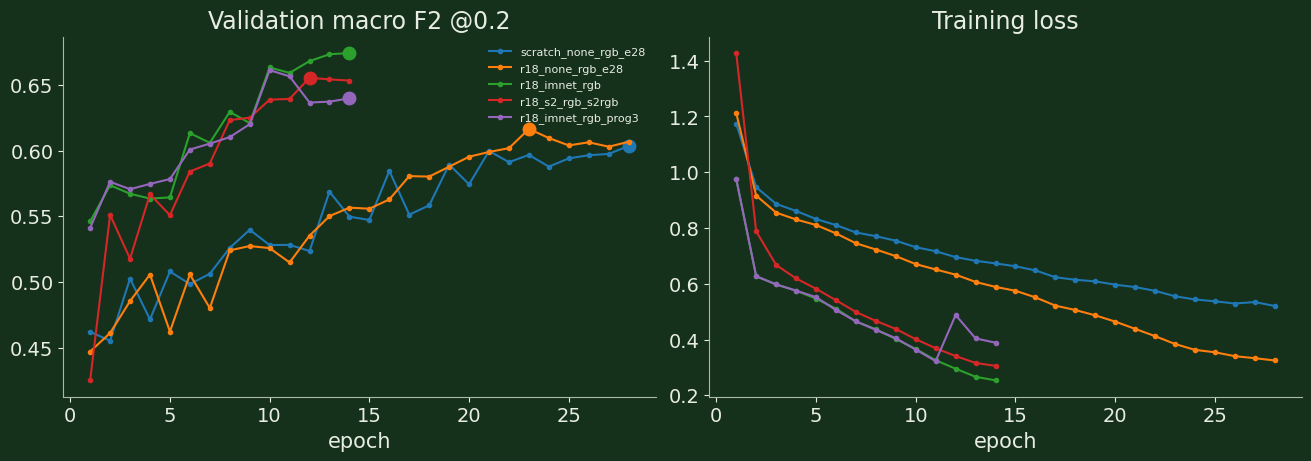

In [ ]:
CURVES = ["scratch_none_rgb_e28", "r18_none_rgb_e28", "r18_imnet_rgb", "r18_s2_rgb_s2rgb", "r18_imnet_rgb_prog3"]

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), constrained_layout=True)
for n in [c for c in CURVES if c in RUN and RUN[c]["hist"]]:
    h, best = RUN[n]["hist"], RUN[n]["meta"].get("best_epoch")
    ep = [e["epoch"] for e in h]
    line, = ax[0].plot(ep, [e["val_macro_f2_fixed"] for e in h], marker=".", label=n)
    ax[1].plot(ep, [e["train_loss"] for e in h], marker=".", color=line.get_color())
    if best in ep:
        ax[0].plot(best, h[ep.index(best)]["val_macro_f2_fixed"], "o", ms=9, color=line.get_color())
ax[0].set(title="Validation macro F2 @0.2", xlabel="epoch"); ax[1].set(title="Training loss", xlabel="epoch")
ax[0].legend(fontsize=8, frameon=False)
fig.savefig(f"{OUT}/fig_training_curves.png"); plt.show()

## 7. Free extras (no training needed)
### Ensemble
Averages the predicted probabilities of several runs, re-tunes thresholds on validation, and scores the result like any other run. Then it bootstraps the ensemble against `FINAL`. Members that make different mistakes help the most, e.g. ImageNet and Sentinel-2 models.

In [ ]:
MEMBERS = ["r18_imnet_rgb_prog3", "r18_s2_rgb_s2rgb", "r18_imnet_rgb"]

def make_ensemble(members, name=None):
    """Adds the averaged run to RUN, so every function above works on it."""
    members = [m for m in members if m in RUN]
    name = name or "ens(" + "+".join(members) + ")"
    RUN[name] = dict(meta={"n_params": sum(RUN[m]["meta"].get("n_params") or 0 for m in members)}, hist=[],
                     vp=np.mean([RUN[m]["vp"] for m in members], 0), vy=first["vy"],
                     tp=np.mean([RUN[m]["tp"] for m in members], 0), ty=first["ty"],
                     vidx=first["vidx"], tidx=first["tidx"])
    _EVAL.pop(name, None)
    return name

ens = make_ensemble(MEMBERS)
show = [m for m in MEMBERS if m in RUN] + [ens]
display(pd.DataFrame({n: {f"{s}_{k}": evaluate(n)[s][k] for s in ("val", "test") for k in ("defor_F2", "macro_F2")}
                      for n in show}).T.round(4))
if FINAL in RUN:
    print(f"bootstrap, ensemble minus {FINAL}:")
    for split in ("val", "test"):
        print(split); display(bootstrap(FINAL, ens, split).round(4))

,val_defor_F2,val_macro_F2,test_defor_F2,test_macro_F2
r18_imnet_rgb_prog3,0.5678,0.6726,0.5632,0.6706
r18_s2_rgb_s2rgb,0.5546,0.6824,0.5746,0.6882
r18_imnet_rgb,0.5861,0.6843,0.6043,0.6963
ens(r18_imnet_rgb_prog3+r18_s2_rgb_s2rgb+r18_imnet_rgb),0.5882,0.6964,0.6058,0.7003


bootstrap, ensemble minus r18_imnet_rgb:
val


,diff,ci_low,ci_high,verdict
defor_F2,0.002086,-0.018314,0.024281,not significant
land_macro_F2,0.014825,0.003101,0.027912,B better
macro_F2,0.012169,0.003382,0.022527,B better


test


,diff,ci_low,ci_high,verdict
defor_F2,0.00152,-0.048105,0.053644,not significant
land_macro_F2,0.00398,-0.011721,0.021246,not significant
macro_F2,0.003944,-0.007883,0.01687,not significant


### Do per-label thresholds help?

No retraining: thresholds are applied to the saved probabilities.
Each scheme is scored on TEST (per-label thresholds were tuned on validation, so validation would flatter them).

In [ ]:
def thr_fixed(v):
    """The same threshold v for all 13 land labels (weather still uses the highest probability)."""
    thr = np.full(len(labels), np.nan); thr[LI] = v
    return thr

def thr_one_tuned(y, p):
    """One shared land threshold, chosen on validation to maximize land macro F2."""
    scores = [f2_from(*counts(y, predict(p, thr_fixed(t))))[LI].mean() for t in GRID]
    return thr_fixed(GRID[int(np.argmax(scores))])

def boot_gain(p_other, p_ref, split="test"):
    """95% interval for (reference - other) in deforestation F2, using the shared bootstrap resamples."""
    d = _boot_f2(p_ref, split)[:, DI].mean(1) - _boot_f2(p_other, split)[:, DI].mean(1)
    lo, hi = np.percentile(d, [2.5, 97.5])
    return f"[{lo:+.3f}, {hi:+.3f}]"

THR_RUNS = ["r18_imnet_rgb", "r18_imnet_rgb_s1", "r18_imnet_rgb_s2",   # final model, 3 seeds
            "r18_imnet_rgb_nobal",                                      # no imbalance handling
            "scratch_none_rgb_e28"]                                     # best model without pretraining

rows = []
for n in [r for r in THR_RUNS if r in RUN]:
    r = RUN[n]
    schemes = {"per-label (tuned)":   evaluate(n)["thr"],
               "one tuned threshold": thr_one_tuned(r["vy"], r["vp"]),
               "fixed 0.2":           thr_fixed(0.2),
               "fixed 0.5":           thr_fixed(0.5)}
    p_ref = predict(r["tp"], schemes["per-label (tuned)"])
    for s, thr in schemes.items():
        pt = predict(r["tp"], thr)
        m = metrics(r["ty"], r["tp"], pt)
        rows.append({"run": n, "thresholds": s,
                     "shared value": "" if s.startswith("per-label") else f"{thr[LI][0]:.2f}",
                     "test_defor_F2": m["defor_F2"], "test_macro_F2": m["macro_F2"],
                     "test_samples_F2": m["samples_F2"],
                     "defor_precision": m["defor_precision"], "defor_recall": m["defor_recall"],
                     "gain from per-label (95% CI)": "" if s.startswith("per-label") else boot_gain(pt, p_ref)})

thr_table = pd.DataFrame(rows).set_index(["run", "thresholds"]).round(3)
thr_table.to_csv(f"{OUT}/threshold_schemes.csv")
display(thr_table)

shared value  test_defor_F2  \
run                  thresholds                                        
r18_imnet_rgb        per-label (tuned)                         0.604   
                     one tuned threshold         0.27          0.604   
                     fixed 0.2                   0.20          0.587   
                     fixed 0.5                   0.50          0.577   
r18_imnet_rgb_s1     per-label (tuned)                         0.560   
                     one tuned threshold         0.34          0.560   
                     fixed 0.2                   0.20          0.561   
                     fixed 0.5                   0.50          0.573   
r18_imnet_rgb_s2     per-label (tuned)                         0.566   
                     one tuned threshold         0.26          0.566   
                     fixed 0.2                   0.20          0.539   
                     fixed 0.5                   0.50          0.590   
r18_imnet_rgb_nobal  per-label (tuned)                         0.583   
                     one tuned threshold         0.11          0.583   
                     fixed 0.2                   0.20          0.498   
                     fixed 0.5                   0.50          0.359   
scratch_none_rgb_e28 per-label (tuned)                         0.539   
                     one tuned threshold         0.45          0.539   
                     fixed 0.2                   0.20          0.396   
                     fixed 0.5                   0.50          0.540   

                                          test_macro_F2  test_samples_F2  \
run                  thresholds                                            
r18_imnet_rgb        per-label (tuned)            0.696            0.900   
                     one tuned threshold          0.696            0.900   
                     fixed 0.2                    0.688            0.896   
                     fixed 0.5                    0.689            0.898   
r18_imnet_rgb_s1     per-label (tuned)            0.690            0.901   
                     one tuned threshold          0.690            0.901   
                     fixed 0.2                    0.680            0.894   
                     fixed 0.5                    0.689            0.899   
r18_imnet_rgb_s2     per-label (tuned)            0.686            0.898   
                     one tuned threshold          0.686            0.898   
                     fixed 0.2                    0.675            0.894   
                     fixed 0.5                    0.692            0.897   
r18_imnet_rgb_nobal  per-label (tuned)            0.682            0.904   
                     one tuned threshold          0.682            0.904   
                     fixed 0.2                    0.646            0.908   
                     fixed 0.5                    0.546            0.892   
scratch_none_rgb_e28 per-label (tuned)            0.654            0.882   
                     one tuned threshold          0.654            0.882   
                     fixed 0.2                    0.607            0.864   
                     fixed 0.5                    0.652            0.879   

                                          defor_precision  defor_recall  \
run                  thresholds                                           
r18_imnet_rgb        per-label (tuned)              0.437         0.700   
                     one tuned threshold            0.437         0.700   
                     fixed 0.2                      0.383         0.718   
                     fixed 0.5                      0.530         0.601   
r18_imnet_rgb_s1     per-label (tuned)              0.452         0.623   
                     one tuned threshold            0.452         0.623   
                     fixed 0.2                      0.382         0.681   
                     fixed 0.5                      0.537         0.600   
r18_imnet_rgb_s2     per-label (t

### Cloudy rule
In the training labels, a chip tagged `cloudy` never has land labels, because nothing on the ground is visible. This switches off all land predictions on chips predicted `cloudy` and shows the effect. It's a quick check of whether the model has already learned that rule.

In [ ]:
def cloudy_rule(pred):
    pred = pred.copy()
    pred[np.ix_(pred[:, labels.index("cloudy")], LI)] = False
    return pred

for n in [REFERENCE, FINAL]:
    if n not in RUN: continue
    e, r = evaluate(n), RUN[n]
    for split, y, p in [("val", r["vy"], r["vp"]), ("test", r["ty"], r["tp"])]:
        before, after = e[split], metrics(y, p, cloudy_rule(e["pred"][split]))
        print(n, split, {k: f"{before[k]:.4f} -> {after[k]:.4f}" for k in ["defor_F2", "macro_F2", "samples_F2"]})

r18_imnet_rgb val {'defor_F2': '0.5861 -> 0.5861', 'macro_F2': '0.6843 -> 0.6836', 'samples_F2': '0.8997 -> 0.8982'}
r18_imnet_rgb test {'defor_F2': '0.6043 -> 0.6043', 'macro_F2': '0.6963 -> 0.6951', 'samples_F2': '0.8999 -> 0.8973'}
r18_imnet_rgb val {'defor_F2': '0.5861 -> 0.5861', 'macro_F2': '0.6843 -> 0.6836', 'samples_F2': '0.8997 -> 0.8982'}
r18_imnet_rgb test {'defor_F2': '0.6043 -> 0.6043', 'macro_F2': '0.6963 -> 0.6951', 'samples_F2': '0.8999 -> 0.8973'}


## 8. Figures for the presentation
### Overview: every configuration
Deforestation F2 for every configuration, grouped by family, with validation and test side by side. Configurations with 3 seeds show the mean, with error bars of ± 1 standard deviation.

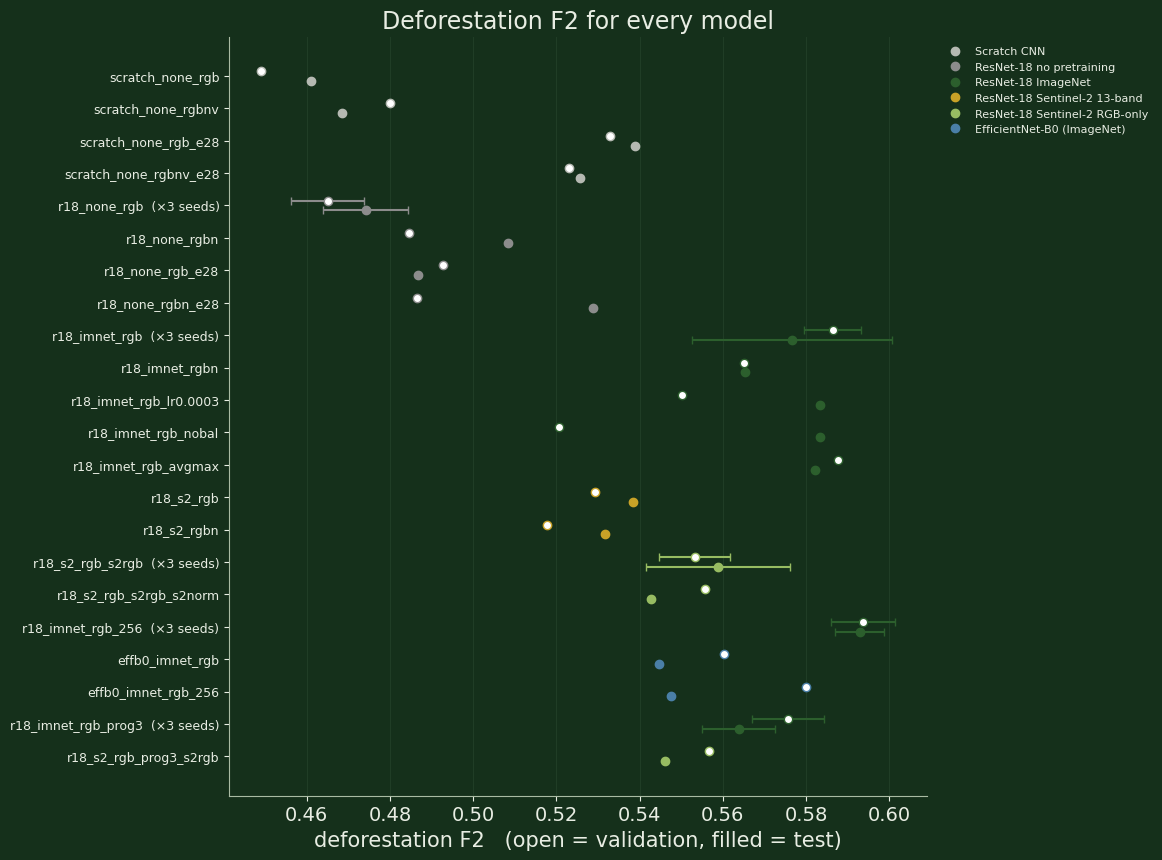

In [ ]:
def config_scores(split):
    """Mean and std of deforestation F2 per configuration (std = 0 when there is only one seed)."""
    rows, done = [], set()
    for n in ORDER:
        base = re.sub(r"_s\d+$", "", n)
        if base in done or base not in RUN: continue
        done.add(base)
        runs = seed_groups().get(base, [base])
        v = np.array([evaluate(r)[split]["defor_F2"] for r in runs])
        rows.append((base, family(base), v.mean(), v.std(ddof=1) if len(v) > 1 else 0, len(v)))
    return rows

FAM_COLORS = {"Scratch CNN": "#B5B9B2", "ResNet-18 no pretraining": "#8C8C8C", "ResNet-18 ImageNet": "#2C5F2D",
              "ResNet-18 Sentinel-2 13-band": "#C9A227", "ResNet-18 Sentinel-2 RGB-only": "#97BC62",
              "EfficientNet-B0 (ImageNet)": "#4A7FA7", "other": "#666666"}
val_rows, test_rows = config_scores("val"), config_scores("test")
fig, ax = plt.subplots(figsize=(9, 0.38 * len(val_rows) + 1.5))
yy = np.arange(len(val_rows))[::-1]
for (n, fam, m, s, k), y in zip(val_rows, yy):
    ax.errorbar(m, y + 0.15, xerr=s, fmt="o", color=FAM_COLORS[fam], mfc="white", capsize=3)
for (n, fam, m, s, k), y in zip(test_rows, yy):
    ax.errorbar(m, y - 0.15, xerr=s, fmt="o", color=FAM_COLORS[fam], capsize=3)
ax.set_yticks(yy); ax.set_yticklabels([f"{n}" + (f"  (×{k} seeds)" if k > 1 else "") for n, _, _, _, k in val_rows], fontsize=9)
ax.set_xlabel("deforestation F2   (open = validation, filled = test)")
for fam, c in FAM_COLORS.items():
    if any(r[1] == fam for r in val_rows): ax.plot([], [], "o", color=c, label=fam)
ax.legend(fontsize=8, frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1)); ax.grid(axis="x", alpha=0.3)
ax.set_title("Deforestation F2 for every model")
fig.savefig(f"{OUT}/fig_overview.png"); plt.show()

### Per-label F2 and precision-recall curves: reference vs. final model (test)

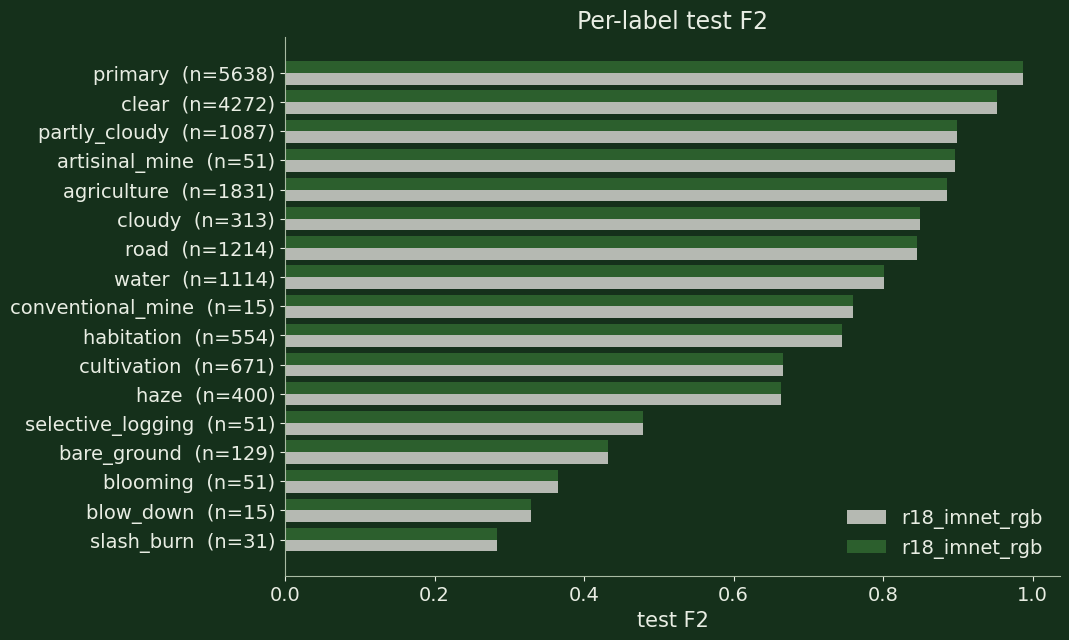

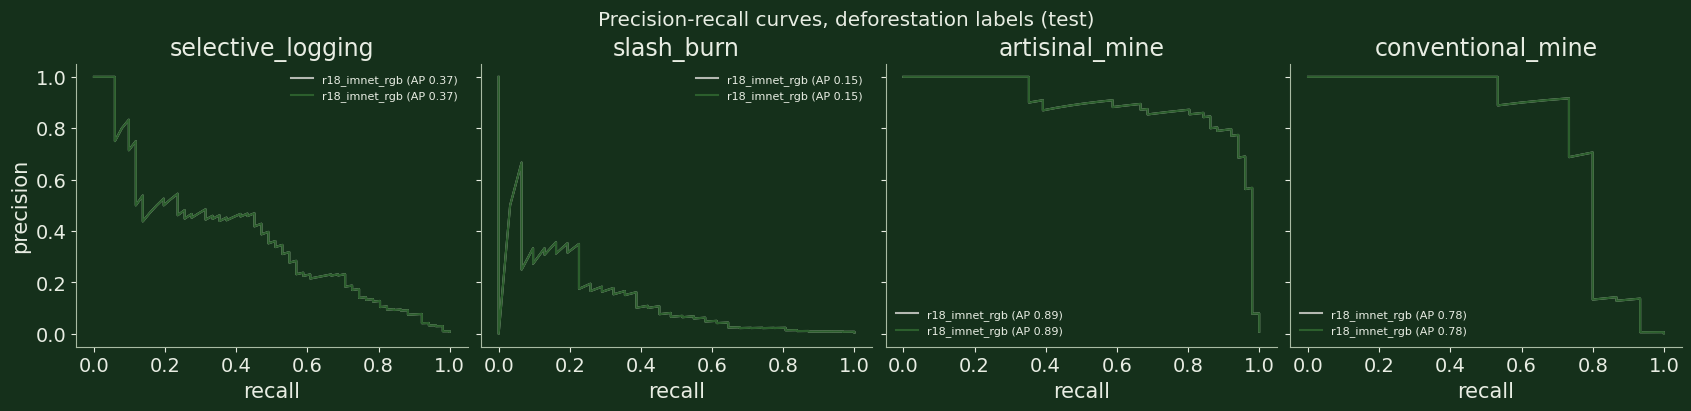

In [ ]:
if REFERENCE in RUN and FINAL in RUN:
    a, b = evaluate(REFERENCE)["per_label"]["test"], evaluate(FINAL)["per_label"]["test"]
    order = a["F2"].sort_values().index
    fig, ax = plt.subplots(figsize=(10, 7)); yy = np.arange(len(order))
    ax.barh(yy - 0.2, a.loc[order, "F2"], 0.4, label=REFERENCE, color="#B5B9B2")
    ax.barh(yy + 0.2, b.loc[order, "F2"], 0.4, label=FINAL, color="#2C5F2D")
    ax.set_yticks(yy); ax.set_yticklabels([f"{l}  (n={a.loc[l, 'positives']})" for l in order])
    ax.set_xlabel("test F2"); ax.legend(frameon=False); ax.set_title("Per-label test F2")
    fig.savefig(f"{OUT}/fig_per_label_f2.png"); plt.show()
    a.join(b, lsuffix="_" + REFERENCE, rsuffix="_" + FINAL).round(3).to_csv(f"{OUT}/per_label_test.csv")

    fig, axes = plt.subplots(1, len(DEFOR), figsize=(4.2 * len(DEFOR), 4), sharey=True, constrained_layout=True)
    for ax, l in zip(axes, DEFOR):
        j = labels.index(l)
        for n, c in [(REFERENCE, "#B5B9B2"), (FINAL, "#2C5F2D")]:
            y, p = RUN[n]["ty"][:, j], RUN[n]["tp"][:, j]
            if y.sum() == 0: continue
            pr, rc, _ = precision_recall_curve(y, p)
            ax.plot(rc, pr, color=c, label=f"{n} (AP {average_precision_score(y, p):.2f})")
        ax.set_title(l); ax.set_xlabel("recall"); ax.legend(fontsize=8, frameon=False)
    axes[0].set_ylabel("precision"); fig.suptitle("Precision-recall curves, deforestation labels (test)")
    fig.savefig(f"{OUT}/fig_pr_curves_defor.png"); plt.show()

### Accuracy vs. cost
Each configuration's seed-42 run: validation deforestation F2 against model size, with marker size showing training time per epoch.

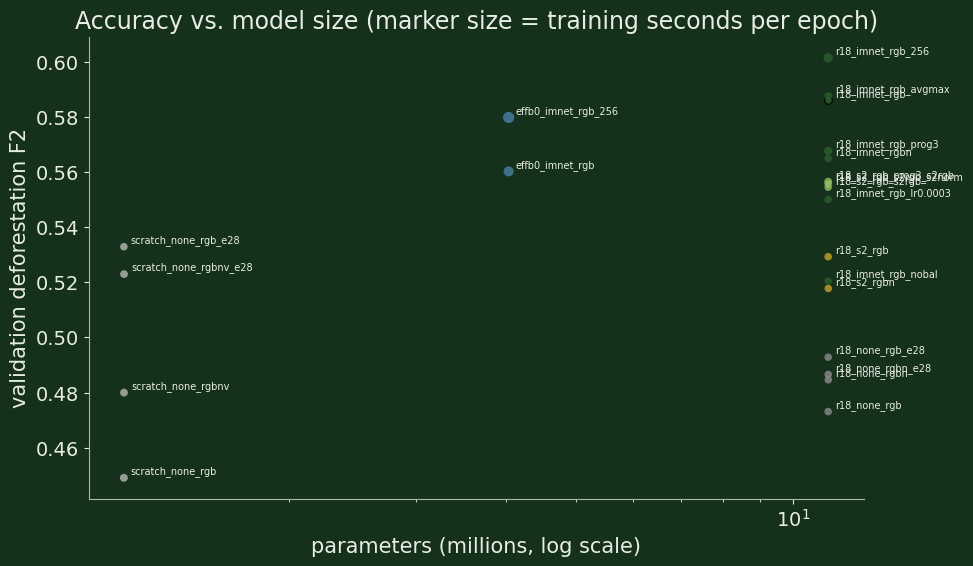

tables and figures saved in /content/drive/MyDrive/amazon_caches/ladder_runs_v2/eval_shared


In [ ]:
pts = [n for n in ORDER if not re.search(r"_s\d+$", n) and RUN[n]["meta"].get("n_params")]
fig, ax = plt.subplots(figsize=(10, 6))
for n in pts:
    s, v = RUN[n]["meta"], evaluate(n)["val"]["defor_F2"]
    ax.scatter(s["n_params"] / 1e6, v, s=20 + 2 * (s.get("train_s_per_epoch") or 0),
               color=FAM_COLORS[family(n)], alpha=0.8, edgecolor="black" if n == FINAL else "none")
    ax.annotate(n, (s["n_params"] / 1e6, v), textcoords="offset points", xytext=(5, 3), fontsize=7)
ax.set_xscale("log"); ax.set_xlabel("parameters (millions, log scale)"); ax.set_ylabel("validation deforestation F2")
ax.set_title("Accuracy vs. model size (marker size = training seconds per epoch)")
fig.savefig(f"{OUT}/fig_accuracy_vs_cost.png"); plt.show()
print("tables and figures saved in", OUT)

In [35]:
# =====================================================================================
# Slide figures for Ladder_Evaluation_v2 (slides 10-13). Add these cells at the end of
# the notebook and run them after sections 1-5. Figures are saved to OUT (ladder_runs_v2/eval).
# All scores are TEST deforestation F2 unless a figure says otherwise.
# =====================================================================================

# ===== Cell 1: deck style (same colors as the slides)
import matplotlib as mpl, matplotlib.pyplot as plt
DECK = dict(bg="#15301B", panel="#1F4426", text="#E8EDE3", muted="#A9BBA3", grid="#3A5E40",
            moss="#97BC62", orange="#E8923A", sky="#8FB8C9", sand="#D8C9A3")
mpl.rcParams.update({
    "figure.facecolor": DECK["bg"], "axes.facecolor": DECK["bg"], "savefig.facecolor": DECK["bg"],
    "text.color": DECK["text"], "axes.labelcolor": DECK["text"], "axes.edgecolor": DECK["muted"],
    "xtick.color": DECK["text"], "ytick.color": DECK["text"], "axes.titlecolor": DECK["text"],
    "grid.color": DECK["grid"], "font.size": 15, "axes.titlesize": 17, "axes.labelsize": 15,
    "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14, "legend.labelcolor": DECK["text"],
    "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 200, "savefig.bbox": "tight"})
NICE = {"selective_logging": "selective logging", "slash_burn": "slash-and-burn",
        "artisinal_mine": "artisanal mine", "conventional_mine": "conventional mine"}

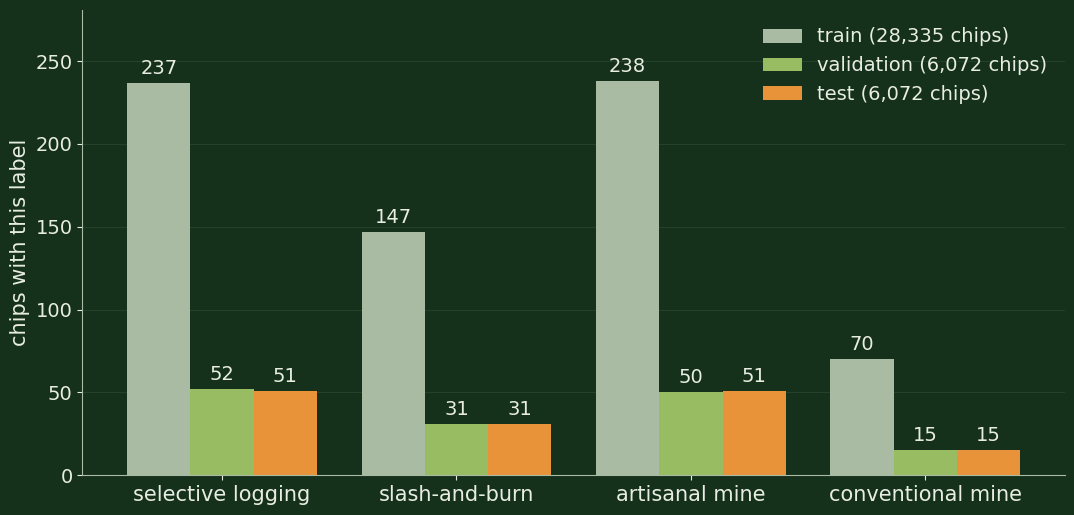

In [ ]:
# ===== Cell 2: slide 10, rare deforestation labels in each split
Y_all = np.load(f"{CACHE}/Y.npy")
spl = np.load(f"{CACHE}/splits.npz")
counts = {s: Y_all[spl[s]][:, DI].sum(0) for s in ("train", "val", "test")}
fig, ax = plt.subplots(figsize=(11, 5.4))
x = np.arange(len(DEFOR)); w = 0.27
for k, (s, col, name) in enumerate([("train", DECK["muted"], "train"), ("val", DECK["moss"], "validation"),
                                    ("test", DECK["orange"], "test")]):
    bars = ax.bar(x + (k - 1) * w, counts[s], w, color=col, label=f"{name} ({len(spl[s]):,} chips)")
    for b in bars:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 3, f"{int(b.get_height())}",
                ha="center", va="bottom", fontsize=14, color=DECK["text"])
ax.set_xticks(x); ax.set_xticklabels([NICE[l] for l in DEFOR], fontsize=15)
ax.set_ylabel("chips with this label"); ax.legend(frameon=False, loc="upper right")
ax.set_ylim(top=max(counts["train"]) * 1.18); ax.grid(axis="y", alpha=0.4); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(f"{OUT}/deck_10a_rare_per_split.png"); plt.show()

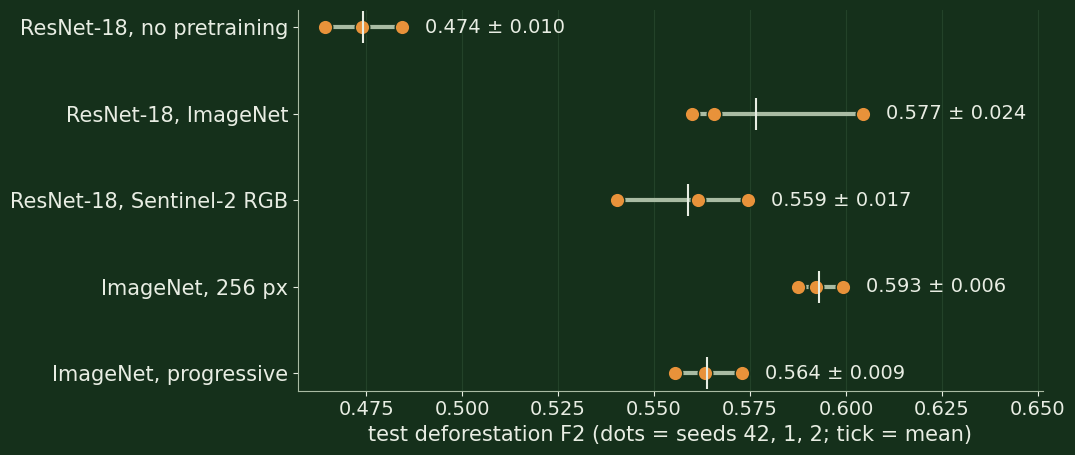

In [ ]:
# ===== Cell 3: slide 10, how much a score moves between seeds (test)
SEED_NAMES = {"r18_none_rgb": "ResNet-18, no pretraining", "r18_imnet_rgb": "ResNet-18, ImageNet",
              "r18_s2_rgb_s2rgb": "ResNet-18, Sentinel-2 RGB", "r18_imnet_rgb_256": "ImageNet, 256 px",
              "r18_imnet_rgb_prog3": "ImageNet, progressive"}
groups = seed_groups()
fig, ax = plt.subplots(figsize=(11, 4.8))
for k, (base, label) in enumerate(SEED_NAMES.items()):
    if base not in groups: continue
    v = np.array([evaluate(r)["test"]["defor_F2"] for r in groups[base]])
    y = len(SEED_NAMES) - 1 - k
    ax.plot([v.min(), v.max()], [y, y], color=DECK["muted"], lw=3, solid_capstyle="round")
    ax.scatter(v, [y] * len(v), s=110, color=DECK["orange"], zorder=3, edgecolor=DECK["bg"])
    ax.scatter([v.mean()], [y], marker="|", s=500, color=DECK["text"], zorder=4)
    ax.text(v.max() + 0.006, y, f"{v.mean():.3f} ± {v.std(ddof=1):.3f}", va="center", fontsize=14)
ax.set_yticks(range(len(SEED_NAMES))); ax.set_yticklabels(list(SEED_NAMES.values())[::-1], fontsize=15)
ax.set_xlabel("test deforestation F2 (dots = seeds 42, 1, 2; tick = mean)")
lo, hi = ax.get_xlim(); ax.set_xlim(lo, hi + 0.04)
ax.grid(axis="x", alpha=0.4); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(f"{OUT}/deck_10b_seed_spread.png"); plt.show()

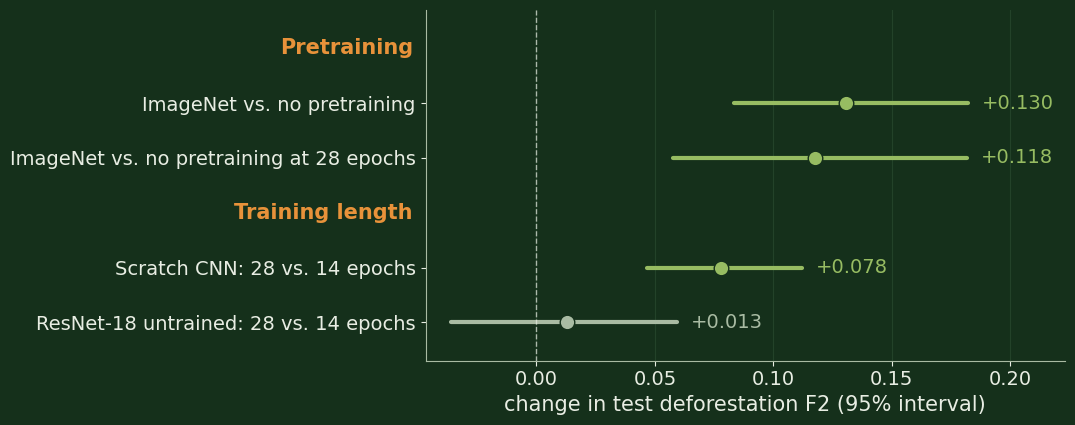

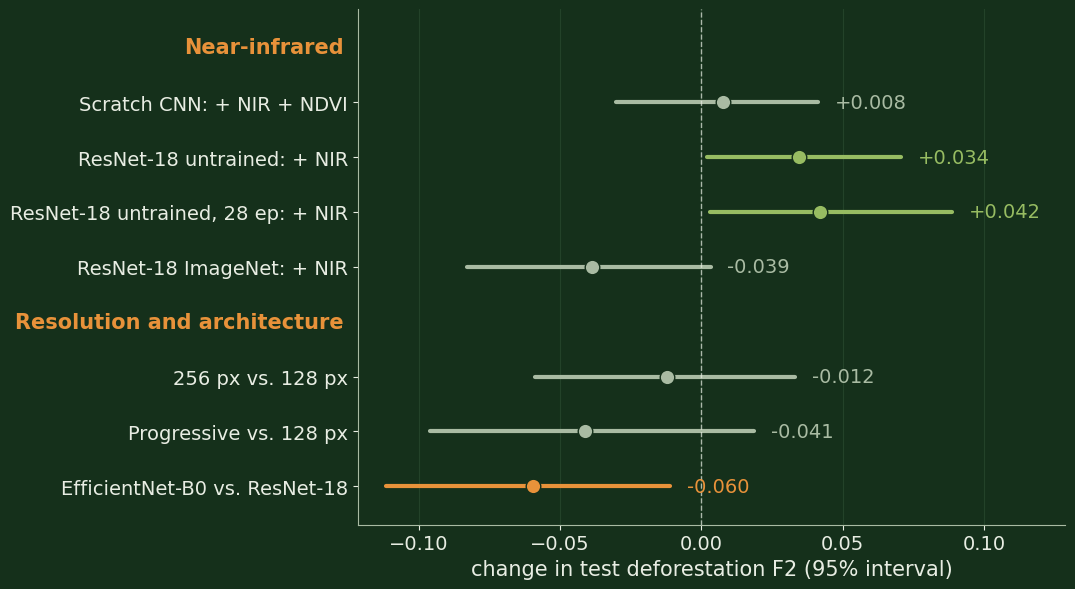

In [29]:
# ===== Cell 4: slides 11-12, forest plots of B - A with 95% bootstrap intervals (test)
def forest(rows, fname, title=None):
    """rows: list of (A, B, label) or a string for a group header. Dot = change in test deforestation F2,
    line = 95% bootstrap interval. Green = clear gain, orange = clear loss, gray = no clear difference."""
    items = [r for r in rows if isinstance(r, str) or (r[0] in RUN and r[1] in RUN)]
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(items) + 1.2))
    y = len(items) - 1
    ylabels, yticks = [], []
    for r in items:
        if isinstance(r, str):                         # group header
            ax.text(-0.02, y, r, transform=ax.get_yaxis_transform(), ha="right", va="center",
                    fontsize=15, fontweight="bold", color=DECK["orange"])
            y -= 1; continue
        a, b, label = r
        bt = bootstrap(a, b, "test").loc["defor_F2"]
        col = DECK["moss"] if bt.ci_low > 0 else DECK["orange"] if bt.ci_high < 0 else DECK["muted"]
        ax.plot([bt.ci_low, bt.ci_high], [y, y], color=col, lw=3, solid_capstyle="round")
        ax.scatter([bt["diff"]], [y], s=110, color=col, zorder=3, edgecolor=DECK["bg"])
        ax.text(bt.ci_high + 0.006, y, f"{bt['diff']:+.3f}", va="center", fontsize=14, color=col)
        ylabels.append(label); yticks.append(y); y -= 1
    ax.axvline(0, color=DECK["text"], lw=1, ls="--", alpha=0.7)
    ax.set_yticks(yticks); ax.set_yticklabels(ylabels, fontsize=14)
    ax.set_ylim(-0.7, len(items) - 0.3)
    lo, hi = ax.get_xlim(); ax.set_xlim(lo, hi + 0.03)
    ax.set_xlabel("change in test deforestation F2 (95% interval)")
    ax.grid(axis="x", alpha=0.4); ax.set_axisbelow(True)
    if title: ax.set_title(title, loc="left")
    fig.tight_layout(); fig.savefig(f"{OUT}/{fname}"); plt.show()

# Slide 11: what matters
forest([
    "Pretraining",
    ("r18_none_rgb", "r18_imnet_rgb", "ImageNet vs. no pretraining"),
    ("r18_none_rgb_e28", "r18_imnet_rgb", "ImageNet vs. no pretraining at 28 epochs"),
    "Training length",
    ("scratch_none_rgb", "scratch_none_rgb_e28", "Scratch CNN: 28 vs. 14 epochs"),
    ("r18_none_rgb", "r18_none_rgb_e28", "ResNet-18 untrained: 28 vs. 14 epochs"),
], "deck_11_what_matters.png")

# Slide 12: what didn't (or only sometimes)
forest([
    "Near-infrared",
    ("scratch_none_rgb", "scratch_none_rgbnv", "Scratch CNN: + NIR + NDVI"),
    ("r18_none_rgb", "r18_none_rgbn", "ResNet-18 untrained: + NIR"),
    ("r18_none_rgb_e28", "r18_none_rgbn_e28", "ResNet-18 untrained, 28 ep: + NIR"),
    ("r18_imnet_rgb", "r18_imnet_rgbn", "ResNet-18 ImageNet: + NIR"),
    "Resolution and architecture",
    ("r18_imnet_rgb", "r18_imnet_rgb_256", "256 px vs. 128 px"),
    ("r18_imnet_rgb", "r18_imnet_rgb_prog3", "Progressive vs. 128 px"),
    ("r18_imnet_rgb", "effb0_imnet_rgb", "EfficientNet-B0 vs. ResNet-18"),
], "deck_12_what_didnt.png")

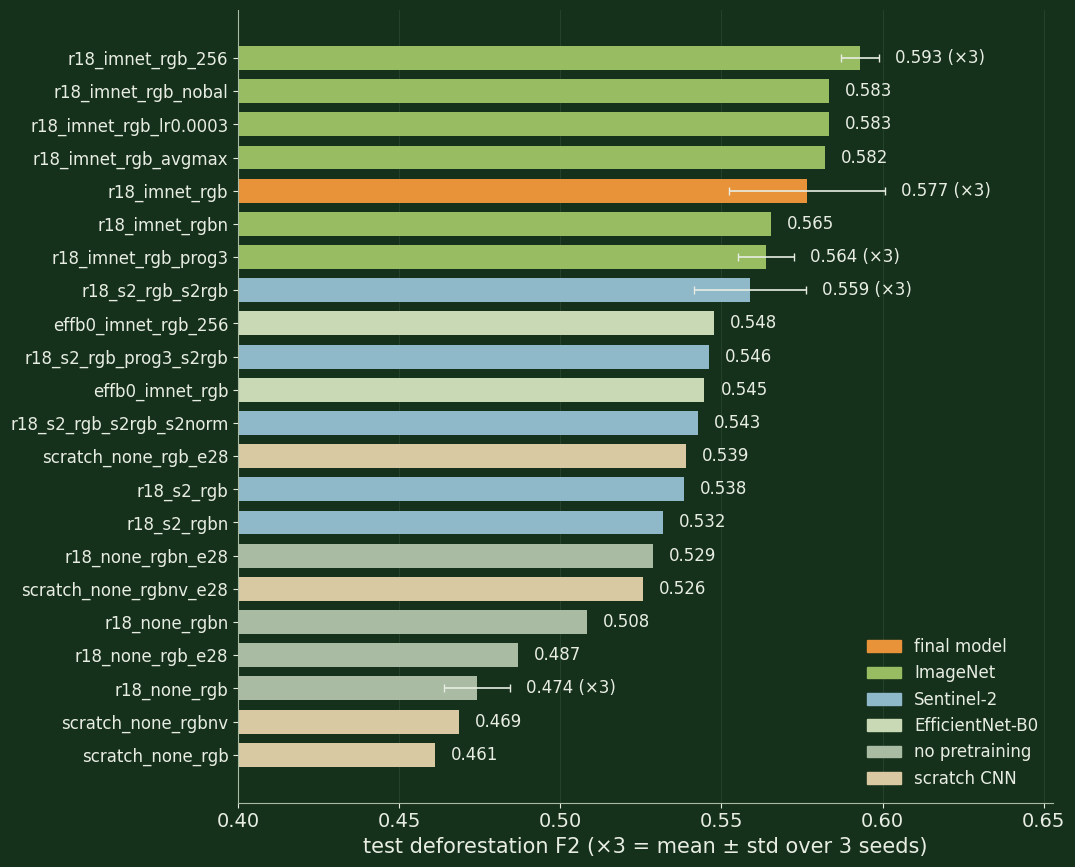

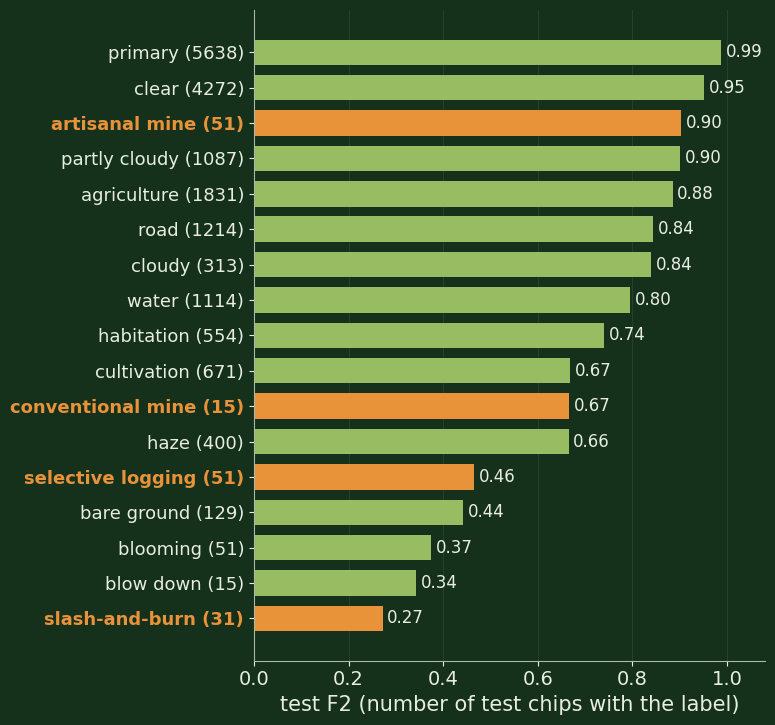

In [ ]:
# ===== Cell 5: slide 13, every configuration (test, mean +/- std over seeds) and per-label F2 of the final model
rows = config_scores("test")                           # from section 8: (name, family, mean, std, n_seeds)
order = sorted(rows, key=lambda r: r[2])
fam_col = {"Scratch CNN": DECK["sand"], "ResNet-18 no pretraining": DECK["muted"], "ResNet-18 ImageNet": DECK["moss"],
           "ResNet-18 Sentinel-2 13-band": DECK["sky"], "ResNet-18 Sentinel-2 RGB-only": DECK["sky"],
           "EfficientNet-B0 (ImageNet)": "#C9D9B5", "other": DECK["muted"]}
fig, ax = plt.subplots(figsize=(11, 0.36 * len(order) + 1.0))
for k, (n, fam, m, sd, ns) in enumerate(order):
    col = DECK["orange"] if n == FINAL else fam_col.get(fam, DECK["muted"])
    ax.barh(k, m, xerr=sd if ns > 1 else None, color=col, height=0.72,
            error_kw=dict(ecolor=DECK["text"], capsize=3, lw=1.2))
    ax.text(m + (sd if ns > 1 else 0) + 0.005, k, f"{m:.3f}" + (f" (×{ns})" if ns > 1 else ""),
            va="center", fontsize=12)
ax.set_yticks(range(len(order))); ax.set_yticklabels([r[0] for r in order], fontsize=12)
ax.set_xlim(0.40, max(r[2] for r in order) + 0.06)
ax.set_xlabel("test deforestation F2 (×3 = mean ± std over 3 seeds)")
handles = [mpl.patches.Patch(color=c, label=f) for f, c in
           [("final model", DECK["orange"]), ("ImageNet", DECK["moss"]), ("Sentinel-2", DECK["sky"]),
            ("EfficientNet-B0", "#C9D9B5"), ("no pretraining", DECK["muted"]), ("scratch CNN", DECK["sand"])]]
ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=12)
ax.grid(axis="x", alpha=0.4); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(f"{OUT}/deck_13a_all_configs.png"); plt.show()

# Per-label test F2 of the final model, mean over its seeds (deforestation labels in orange)
fin = seed_groups().get(FINAL, [FINAL])
f2 = np.mean([evaluate(r)["per_label"]["test"]["F2"].values for r in fin], 0)
pos = evaluate(FINAL)["per_label"]["test"]["positives"].values
idx = np.argsort(f2)
fig, ax = plt.subplots(figsize=(8, 7.5))
cols = [DECK["orange"] if labels[j] in DEFOR else DECK["moss"] for j in idx]
ax.barh(range(len(idx)), f2[idx], color=cols, height=0.72)
for k, j in enumerate(idx):
    ax.text(f2[j] + 0.01, k, f"{f2[j]:.2f}", va="center", fontsize=12)
ax.set_yticks(range(len(idx)))
ax.set_yticklabels([f"{NICE.get(labels[j], labels[j].replace('_', ' '))} ({pos[j]})" for j in idx], fontsize=13)
for t, j in zip(ax.get_yticklabels(), idx):
    if labels[j] in DEFOR: t.set_color(DECK["orange"]); t.set_fontweight("bold")
ax.set_xlim(0, 1.08); ax.set_xlabel("test F2 (number of test chips with the label)")
ax.grid(axis="x", alpha=0.4); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(f"{OUT}/deck_13b_final_per_label.png"); plt.show()

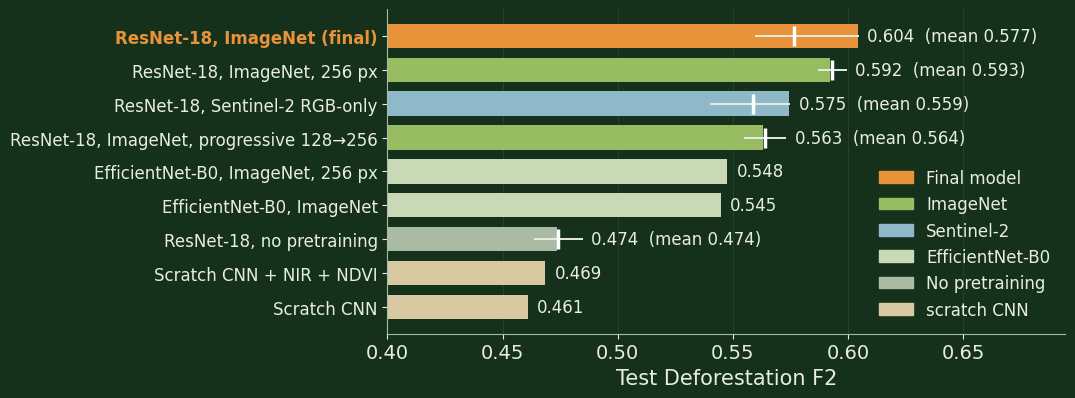

In [33]:
# ===== Slide 13 (redraw): every configuration, all bars = the seed-42 run (the same kind of number for everyone).
# Where a configuration has 3 seeds, the whisker spans the lowest to the highest seed and the white tick marks the mean.
# Readable names instead of run names. Needs the deck-style cell (Cell 1 of the slide-figure cells).
READABLE = {
    "scratch_none_rgb":    "Scratch CNN",
    "scratch_none_rgbnv":  "Scratch CNN + NIR + NDVI",
    "r18_none_rgb":        "ResNet-18, no pretraining",
    "r18_imnet_rgb":       "ResNet-18, ImageNet (final)",
    "r18_s2_rgb_s2rgb":    "ResNet-18, Sentinel-2 RGB-only",
    "r18_imnet_rgb_256":   "ResNet-18, ImageNet, 256 px",
    "effb0_imnet_rgb":     "EfficientNet-B0, ImageNet",
    "effb0_imnet_rgb_256": "EfficientNet-B0, ImageNet, 256 px",
    "r18_imnet_rgb_prog3": "ResNet-18, ImageNet, progressive 128→256",
}
def fam_color(n):
    if n == FINAL: return DECK["orange"]
    if n.startswith("scratch"): return DECK["sand"]
    if n.startswith("effb0"): return "#C9D9B5"
    if n.startswith("r18_s2"): return DECK["sky"]
    if n.startswith("r18_none"): return DECK["muted"]
    return DECK["moss"]

groups = seed_groups()
bases = [n for n in ORDER if not re.search(r"_s\d+$", n)]
bases = [n for n in bases if n in READABLE]          # only the runs listed in READABLE
score = {n: evaluate(n)["test"]["defor_F2"] for n in bases}            # seed-42 run
order = sorted(bases, key=lambda n: score[n])
fig, ax = plt.subplots(figsize=(11, 0.36 * len(order) + 1.0))
for k, n in enumerate(order):
    ax.barh(k, score[n], color=fam_color(n), height=0.72)
    if n in groups:                                                     # 3 seeds: range + mean
        v = np.array([evaluate(r)["test"]["defor_F2"] for r in groups[n]])
        ax.plot([v.min(), v.max()], [k, k], color=DECK["text"], lw=1.4)
        ax.plot([v.mean()], [k], marker="|", ms=14, mew=2.5, color="white")
        ax.text(v.max() + 0.004, k, f"{score[n]:.3f}  (mean {v.mean():.3f})", va="center", fontsize=12)
    else:
        ax.text(score[n] + 0.004, k, f"{score[n]:.3f}", va="center", fontsize=12)
ax.set_yticks(range(len(order)))
ax.set_yticklabels([READABLE.get(n, n) for n in order], fontsize=12)
for t, n in zip(ax.get_yticklabels(), order):
    if n == FINAL: t.set_color(DECK["orange"]); t.set_fontweight("bold")
ax.set_xlim(max(0, round(min(score.values()) - 0.06, 2)), max(score.values()) + 0.09)
ax.set_xlabel("Test Deforestation F2")
handles = [mpl.patches.Patch(color=c, label=f) for f, c in
           [("Final model", DECK["orange"]), ("ImageNet", DECK["moss"]), ("Sentinel-2", DECK["sky"]),
            ("EfficientNet-B0", "#C9D9B5"), ("No pretraining", DECK["muted"]), ("scratch CNN", DECK["sand"])]]
ax.legend(handles=handles, loc="lower right", frameon=False, fontsize=12)
ax.grid(axis="x", alpha=0.4); ax.set_axisbelow(True)
fig.tight_layout(); fig.savefig(f"{OUT}/deck_13a_all_configs.png"); plt.show()

runs pooled: ['r18_imnet_rgb', 'r18_imnet_rgb_s1', 'r18_imnet_rgb_s2']  (18,216 chip predictions)


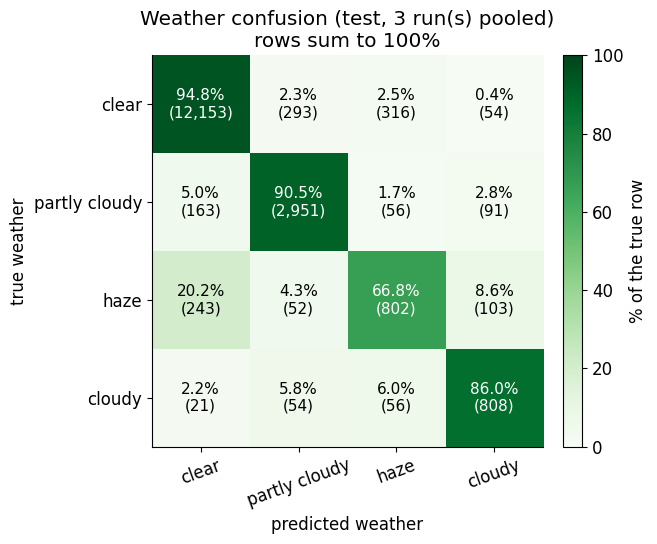

weather accuracy: 0.918


,pred clear,pred partly_cloudy,pred haze,pred cloudy
true clear,12153,293,316,54
true partly_cloudy,163,2951,56,91
true haze,243,52,802,103
true cloudy,21,54,56,808


In [7]:
# =====================================================================================
# Where does the model mix up labels?  Add these two cells at the end of Ladder_Evaluation_v2
# and run them after sections 1-2 (they use RUN, evaluate, seed_groups, labels, WI, LI, DEFOR, OUT).
# Everything is on the TEST set, using the same thresholds as the rest of the notebook.
# By default the counts are pooled over the final model's 3 seeds (3x as many chips -> steadier picture).
# =====================================================================================

# ===== Cell 1: weather confusion matrix (each chip has exactly one weather label, so a normal matrix works)
import numpy as np, pandas as pd, matplotlib.pyplot as plt

CM_RUNS = seed_groups().get(FINAL, [FINAL])          # e.g. ["r18_imnet_rgb", "r18_imnet_rgb_s1", "r18_imnet_rgb_s2"]
                                                     # use [FINAL] for the seed-42 run only
Y_true = np.concatenate([RUN[r]["ty"] for r in CM_RUNS]).astype(bool)
Y_pred = np.concatenate([evaluate(r)["pred"]["test"] for r in CM_RUNS]).astype(bool)
print(f"runs pooled: {CM_RUNS}  ({len(Y_true):,} chip predictions)")

W_NAMES = [labels[j] for j in WI]
has_w = Y_true[:, WI].sum(1) == 1                    # skip any chip without exactly one true weather label
t_w = Y_true[has_w][:, WI].argmax(1)
p_w = Y_pred[has_w][:, WI].argmax(1)
cm = np.zeros((4, 4), int)
for t, p in zip(t_w, p_w):
    cm[t, p] += 1
cm_pct = cm / cm.sum(1, keepdims=True) * 100         # each row sums to 100%: "of chips that are truly X, % predicted Y"

fig, ax = plt.subplots(figsize=(6.8, 5.6))
im = ax.imshow(cm_pct, cmap="Greens", vmin=0, vmax=100)
for i in range(4):
    for j in range(4):
        ax.text(j, i, f"{cm_pct[i, j]:.1f}%\n({cm[i, j]:,})", ha="center", va="center", fontsize=11,
                color="white" if cm_pct[i, j] > 55 else "black")
ax.set_xticks(range(4)); ax.set_xticklabels([w.replace("_", " ") for w in W_NAMES], rotation=20)
ax.set_yticks(range(4)); ax.set_yticklabels([w.replace("_", " ") for w in W_NAMES])
ax.set_xlabel("predicted weather"); ax.set_ylabel("true weather")
ax.set_title(f"Weather confusion (test, {len(CM_RUNS)} run(s) pooled)\nrows sum to 100%")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04, label="% of the true row")
fig.tight_layout(); fig.savefig(f"{OUT}/confusion_weather.png"); plt.show()
print(f"weather accuracy: {(t_w == p_w).mean():.3f}")
display(pd.DataFrame(cm, index=[f"true {w}" for w in W_NAMES], columns=[f"pred {w}" for w in W_NAMES]))

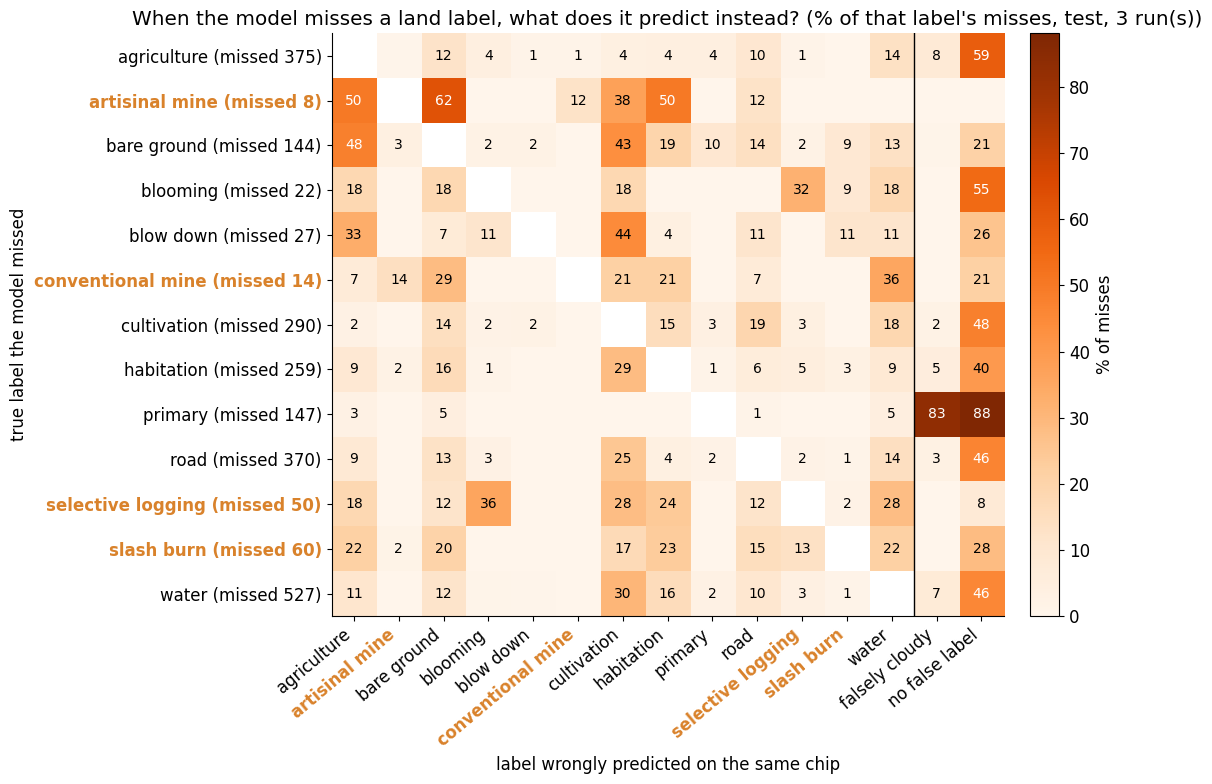

,missed,predicted instead,chips,% of misses,deforestation
11,artisinal_mine,bare_ground,5,62.5,True
10,artisinal_mine,agriculture,4,50.0,True
13,artisinal_mine,habitation,4,50.0,True
12,artisinal_mine,cultivation,3,37.5,True
73,selective_logging,blooming,18,36.0,True
39,conventional_mine,water,5,35.7,True
36,conventional_mine,bare_ground,4,28.6,True
74,selective_logging,cultivation,14,28.0,True
77,selective_logging,water,14,28.0,True
75,selective_logging,habitation,12,24.0,True


In [8]:
# ===== Cell 2: land labels, "missed A, wrongly predicted B instead"
# For every chip where true label A was MISSED, which labels did the model ADD that the chip doesn't have?
# Row A, column B = % of A's misses where B was falsely predicted on the same chip.
# Only WRONG predictions count, so labels that truly appear together (e.g. slash-and-burn + agriculture) are not errors.
# Extra columns: "falsely cloudy" (the model called the chip cloudy, which switches off land labels in the data's logic)
# and "no false label" (the miss came with no wrong label at all: the model just didn't see it).
L_NAMES = [labels[j] for j in LI]
missed = Y_true[:, LI] & ~Y_pred[:, LI]                       # (chips, 13): A was missed
added = Y_pred[:, LI] & ~Y_true[:, LI]                        # (chips, 13): B was falsely predicted
ci = labels.index("cloudy")
false_cloudy = Y_pred[:, ci] & ~Y_true[:, ci]

rows, n_miss = [], []
for a in range(len(LI)):
    m = missed[:, a]
    n_miss.append(int(m.sum()))
    if m.sum() == 0:
        rows.append([np.nan] * (len(LI) + 2)); continue
    pct_b = added[m].mean(0) * 100                            # share of A's misses with each false B
    pct_b[a] = np.nan                                         # a label can't be "added" on its own miss
    rows.append(list(pct_b) + [false_cloudy[m].mean() * 100, (~added[m].any(1)).mean() * 100])
cols = [l.replace("_", " ") for l in L_NAMES] + ["falsely cloudy", "no false label"]
mix = pd.DataFrame(rows, index=[f"{l.replace('_', ' ')} (missed {n})" for l, n in zip(L_NAMES, n_miss)], columns=cols)

fig, ax = plt.subplots(figsize=(14, 8))
im = ax.imshow(mix.values, cmap="Oranges", vmin=0, vmax=min(100, np.nanmax(mix.values[:, :-1]) * 1.05 + 1))
for i in range(mix.shape[0]):
    for j in range(mix.shape[1]):
        v = mix.values[i, j]
        if not np.isnan(v) and v >= 1:
            ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=10, color="white" if v > 45 else "black")
ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, rotation=40, ha="right")
ax.set_yticks(range(len(mix))); ax.set_yticklabels(mix.index)
for t in ax.get_yticklabels() + ax.get_xticklabels():         # deforestation labels in orange
    if t.get_text().split(" (")[0].replace(" ", "_") in DEFOR:
        t.set_color("#D9822B"); t.set_fontweight("bold")
ax.axvline(len(LI) - 0.5, color="black", lw=1)
ax.set_xlabel("label wrongly predicted on the same chip"); ax.set_ylabel("true label the model missed")
ax.set_title(f"When the model misses a land label, what does it predict instead? (% of that label's misses, test, {len(CM_RUNS)} run(s))")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="% of misses")
fig.tight_layout(); fig.savefig(f"{OUT}/confusion_land_mixups.png"); plt.show()

# The most common mix-ups as a list (at least 3 occurrences), deforestation labels first
pairs = []
for a, la in enumerate(L_NAMES):
    m = missed[:, a]
    for b, lb in enumerate(L_NAMES):
        if a != b and m.sum():
            k = int((m & added[:, b]).sum())
            if k >= 3:
                pairs.append({"missed": la, "predicted instead": lb, "chips": k,
                              "% of misses": round(100 * k / m.sum(), 1), "deforestation": la in DEFOR})
top = pd.DataFrame(pairs).sort_values(["deforestation", "% of misses"], ascending=[False, False])
top.to_csv(f"{OUT}/confusion_land_pairs.csv", index=False)
display(top.head(25))

In [16]:
# =====================================================================
# EVALUATION NOTEBOOK (Ladder_Evaluation_v2): new cell, add after section 5
# Compares ResNet-34 with ResNet-18 using the shared threshold, test set as the main number.
# =====================================================================
R34_QUESTIONS = {
    "Depth: ResNet-34 vs. ResNet-18 (ImageNet RGB)": [
        ("r18_imnet_rgb",     "r34_imnet_rgb",     "ResNet-34 vs. ResNet-18, 128 px"),
        ("r18_imnet_rgb_256", "r34_imnet_rgb_256", "ResNet-34 vs. ResNet-18, 256 px"),
        ("r34_imnet_rgb",     "r34_imnet_rgb_256", "ResNet-34: 256 vs. 128 px"),
    ],
}
r34_cmp = compare_all(R34_QUESTIONS)                 # seed-42 runs, paired bootstrap
r34_cmp.to_csv(f"{OUT}/comparisons_resnet34.csv")
display(r34_cmp.droplevel(0).drop(columns=["A", "B"]))

# 3-seed means, so one lucky or unlucky seed doesn't decide it
CONFIGS = ["r18_imnet_rgb", "r34_imnet_rgb", "r18_imnet_rgb_256", "r34_imnet_rgb_256"]
rows = []
for base in CONFIGS:
    runs = seed_groups().get(base, [base] if base in RUN else [])
    if not runs:
        print(f"[skip] {base}: not trained yet"); continue
    t = np.array([evaluate(r)["test"]["defor_F2"] for r in runs])
    m = np.array([evaluate(r)["test"]["macro_F2"] for r in runs])
    meta = RUN[runs[0]]["meta"]
    rows.append({"configuration": base, "seeds": len(runs),
                 "test defor F2": f"{t.mean():.3f} ± {t.std(ddof=1) if len(t) > 1 else 0:.3f}",
                 "each seed": " / ".join(f"{x:.3f}" for x in t),
                 "test macro F2": f"{m.mean():.3f}",
                 "params (M)": round((meta.get("n_params") or 0) / 1e6, 1),
                 "s / epoch": meta.get("train_s_per_epoch")})
display(pd.DataFrame(rows).set_index("configuration"))

,A val,B val,Δ val,val 95% CI,val verdict,Δ val macro,Δ test,test 95% CI,test verdict
question,,,,,,,,,
"ResNet-34 vs. ResNet-18, 128 px",0.586,0.564,-0.022,"[-0.066, +0.016]",not significant,0.002,-0.015,"[-0.066, +0.038]",not significant
"ResNet-34 vs. ResNet-18, 256 px",0.602,0.574,-0.028,"[-0.061, +0.003]",not significant,-0.007,-0.019,"[-0.044, +0.004]",not significant
ResNet-34: 256 vs. 128 px,0.564,0.574,0.010,"[-0.029, +0.056]",not significant,-0.003,-0.016,"[-0.061, +0.025]",not significant


,seeds,test defor F2,each seed,test macro F2,params (M),s / epoch
configuration,,,,,,
r18_imnet_rgb,3,0.577 ± 0.024,0.604 / 0.560 / 0.566,0.691,11.2,5.2
r34_imnet_rgb,3,0.588 ± 0.003,0.589 / 0.590 / 0.585,0.697,21.3,7.4
r18_imnet_rgb_256,3,0.593 ± 0.006,0.592 / 0.599 / 0.587,0.695,11.2,12.2
r34_imnet_rgb_256,3,0.588 ± 0.018,0.573 / 0.608 / 0.583,0.690,21.3,15.1


In [17]:
# Every run with saved predictions, in training order (planned runs first, then extras such as ResNet-34)
real = [n for n in ORDER if n in RUN and RUN[n]["meta"]]   # leaves out ensembles built inside the notebook
print(f"{len(real)} runs:")
for n in real:
    print(n)

38 runs:
scratch_none_rgb
scratch_none_rgbnv
scratch_none_rgb_e28
scratch_none_rgbnv_e28
r18_none_rgb
r18_none_rgb_s1
r18_none_rgb_s2
r18_none_rgbn
r18_none_rgb_e28
r18_none_rgbn_e28
r18_imnet_rgb
r18_imnet_rgb_s1
r18_imnet_rgb_s2
r18_imnet_rgbn
r18_imnet_rgb_lr0.0003
r18_imnet_rgb_nobal
r18_imnet_rgb_avgmax
r18_s2_rgb
r18_s2_rgbn
r18_s2_rgb_s2rgb
r18_s2_rgb_s2rgb_s1
r18_s2_rgb_s2rgb_s2
r18_s2_rgb_s2rgb_s2norm
r18_imnet_rgb_256
r18_imnet_rgb_256_s1
r18_imnet_rgb_256_s2
effb0_imnet_rgb
effb0_imnet_rgb_256
r18_imnet_rgb_prog3
r18_imnet_rgb_prog3_s1
r18_imnet_rgb_prog3_s2
r18_s2_rgb_prog3_s2rgb
r34_imnet_rgb
r34_imnet_rgb_256
r34_imnet_rgb_256_s1
r34_imnet_rgb_256_s2
r34_imnet_rgb_s1
r34_imnet_rgb_s2


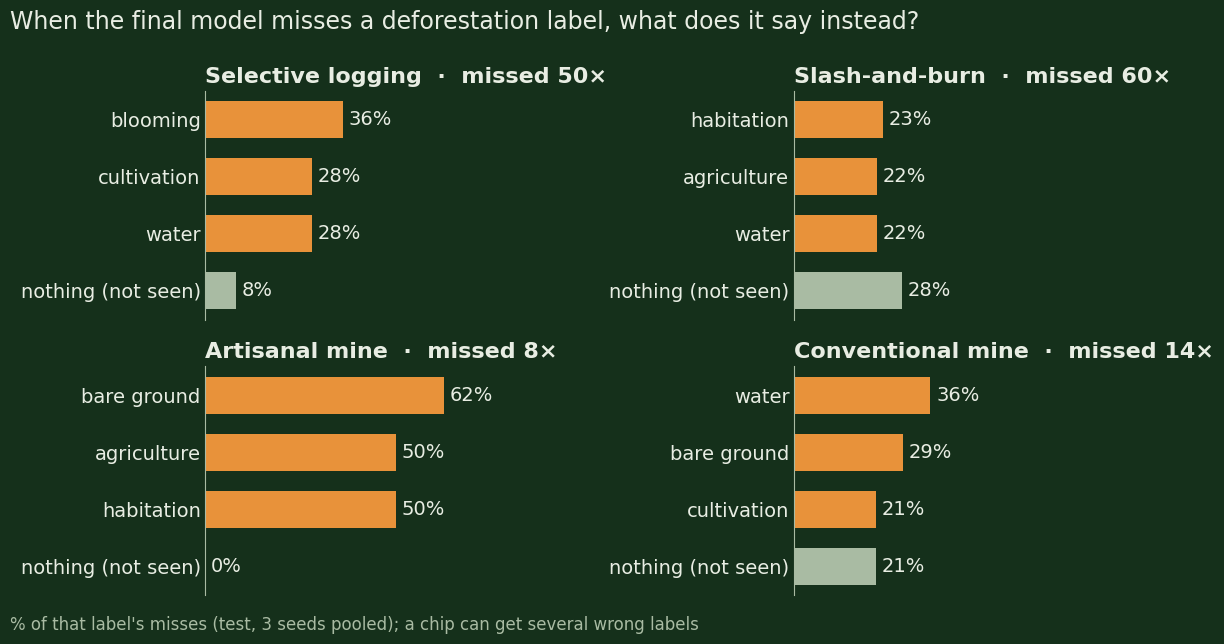

,missed,blooming,cultivation,water,not_seen,habitation,agriculture,bare ground
selective_logging,50.0,36.0,28.0,28.0,8.0,NaN,NaN,NaN
slash_burn,60.0,NaN,NaN,22.0,28.0,23.0,22.0,NaN
artisinal_mine,8.0,NaN,NaN,NaN,0.0,50.0,50.0,62.0
conventional_mine,14.0,NaN,21.0,36.0,21.0,NaN,NaN,29.0


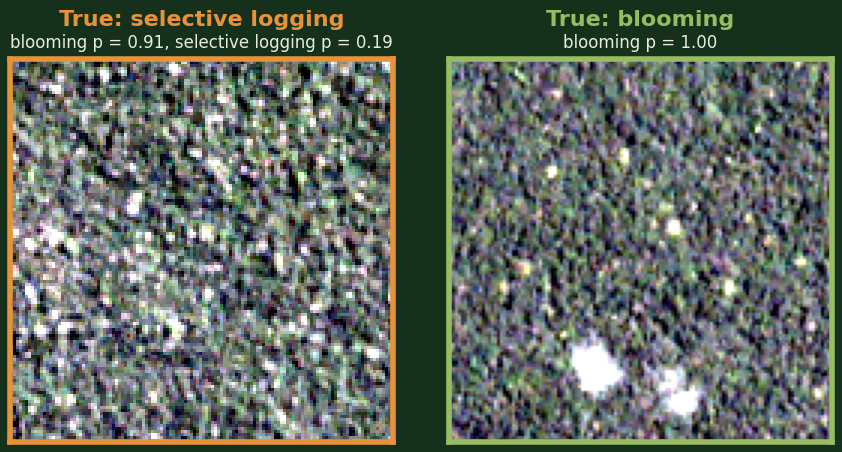

chips used (cache indices): (27257, 17773)
other logging candidates (cache indices), try them with PAIR = (index, blooming index): [36056, 36563, 13889, 16369]


,missed,blooming,cultivation,water,not_seen,habitation,agriculture,bare ground
selective_logging,50.0,36.0,28.0,28.0,8.0,NaN,NaN,NaN
slash_burn,60.0,NaN,NaN,22.0,28.0,23.0,22.0,NaN
artisinal_mine,8.0,NaN,NaN,NaN,0.0,50.0,50.0,62.0
conventional_mine,14.0,NaN,21.0,36.0,21.0,NaN,NaN,29.0


In [39]:
# =====================================================================================
# Deck figures: where the final model mixes up deforestation labels
# Add at the end of Ladder_Evaluation_v2. Needs sections 1-2 (the deck style is included below).
# Test set, the notebook's thresholds. Saves deck_mixup_bars.png and deck_lookalike.png to OUT.
# =====================================================================================
import json, numpy as np, matplotlib.pyplot as plt

assert FINAL == "r18_imnet_rgb", f"FINAL is {FINAL!r}: set FINAL = 'r18_imnet_rgb' (and rerun its cell) first"

# --- deck style (included here so this cell doesn't depend on another one)
import matplotlib as mpl, matplotlib.pyplot as plt
DECK = dict(bg="#15301B", panel="#1F4426", text="#E8EDE3", muted="#A9BBA3", grid="#3A5E40",
            moss="#97BC62", orange="#E8923A", sky="#8FB8C9", sand="#D8C9A3")
DEFOR_LABELS = ["selective_logging", "slash_burn", "artisinal_mine", "conventional_mine"]

def deck_style():
    """Dark background, light text, larger fonts (readable when projected)."""
    mpl.rcParams.update({
        "figure.facecolor": DECK["bg"], "axes.facecolor": DECK["bg"], "savefig.facecolor": DECK["bg"],
        "text.color": DECK["text"], "axes.labelcolor": DECK["text"], "axes.edgecolor": DECK["muted"],
        "xtick.color": DECK["text"], "ytick.color": DECK["text"], "axes.titlecolor": DECK["text"],
        "grid.color": DECK["grid"], "font.size": 15, "axes.titlesize": 17, "axes.labelsize": 15,
        "xtick.labelsize": 14, "ytick.labelsize": 14, "legend.fontsize": 14, "legend.labelcolor": DECK["text"],
        "axes.spines.top": False, "axes.spines.right": False, "savefig.dpi": 200, "savefig.bbox": "tight"})
deck_style()

NICE = {"selective_logging": "selective logging", "slash_burn": "slash-and-burn", "artisinal_mine": "artisanal mine",
        "conventional_mine": "conventional mine", "bare_ground": "bare ground", "blow_down": "blow down",
        "partly_cloudy": "partly cloudy"}
nice = lambda l: NICE.get(l, l.replace("_", " "))


# ===== Cell A: one small bar chart per deforestation label ("when it misses X, what does it say instead?")
TOP_K = 3                                                    # mix-ups shown per label (plus "nothing")
runs = seed_groups().get(FINAL, [FINAL])                     # the final model's 3 seeds, pooled
Yt = np.concatenate([RUN[r]["ty"] for r in runs]).astype(bool)
Yp = np.concatenate([evaluate(r)["pred"]["test"] for r in runs]).astype(bool)
LAND = [labels[j] for j in LI]
wrong_land = Yp[:, LI] & ~Yt[:, LI]                          # land labels predicted but not on the chip

fig, axes = plt.subplots(2, 2, figsize=(12, 6.2))
summary = {}
for ax, a in zip(axes.ravel(), DEFOR):
    ja = labels.index(a)
    m = Yt[:, ja] & ~Yp[:, ja]                               # chips where label a was missed
    n = int(m.sum())
    shares = {b: wrong_land[m, k].mean() * 100 for k, b in enumerate(LAND) if b != a} if n else {}
    top = sorted(shares.items(), key=lambda kv: -kv[1])[:TOP_K]
    not_seen = (~wrong_land[m].any(1)).mean() * 100 if n else 0
    names = [nice(b) for b, _ in top] + ["nothing (not seen)"]
    vals = [v for _, v in top] + [not_seen]
    cols = [DECK["orange"]] * len(top) + [DECK["muted"]]
    y = np.arange(len(vals))[::-1]
    ax.barh(y, vals, color=cols, height=0.65)
    for yy, v in zip(y, vals):
        ax.text(v + 1.5, yy, f"{v:.0f}%", va="center", fontsize=14, color=DECK["text"])
    ax.set_yticks(y); ax.set_yticklabels(names, fontsize=14)
    ax.set_xlim(0, 100); ax.set_xticks([])
    ax.spines["bottom"].set_visible(False); ax.tick_params(length=0)
    ax.set_title(f"{nice(a).capitalize()}  ·  missed {n}×", loc="left", fontsize=16,
                 color=DECK["text"], fontweight="bold")
    summary[a] = dict(missed=n, **{nice(b): round(v) for b, v in top}, not_seen=round(not_seen))
fig.suptitle("When the final model misses a deforestation label, what does it say instead?",
             fontsize=17, color=DECK["text"], x=0.01, ha="left")
fig.text(0.01, -0.02, f"% of that label's misses (test, {len(runs)} seeds pooled); a chip can get several wrong labels",
         fontsize=12, color=DECK["muted"])
fig.tight_layout(); fig.savefig(f"{OUT}/deck_mixup_bars.png"); plt.show()
display(pd.DataFrame(summary).T)


# ===== Cell B: a look-alike pair: a selective-logging chip the model called blooming, next to a real blooming chip
# Chips are picked from the seed-42 final run. To choose them yourself: PAIR = (logging chip index, blooming chip index)
PAIR = None
A, B = "selective_logging", "blooming"
X128 = np.load(f"{CACHE}/X.npy", mmap_mode="r")             # the 128 px image cache (same folder as labels.json)

def natural_rgb(x, lo=2, hi=98, gamma=0.9):
    """(channels, H, W) chip -> (H, W, 3) image, each band stretched on its own (display only)."""
    img = np.transpose(np.asarray(x[:3], dtype=np.float32), (1, 2, 0))
    out = np.empty_like(img)
    for c in range(3):
        lo_, hi_ = np.percentile(img[..., c], [lo, hi])
        out[..., c] = np.clip((img[..., c] - lo_) / (hi_ - lo_ + 1e-6), 0, 1)
    return out ** gamma

r = RUN[FINAL]; ty, tp, tidx = r["ty"].astype(bool), r["tp"], r["tidx"]
pred = evaluate(FINAL)["pred"]["test"].astype(bool)
ja, jb, jc = labels.index(A), labels.index(B), labels.index("clear")
if PAIR is None:
    # logging chip: has selective logging, model missed it AND wrongly said blooming; most confident "blooming" first
    c1 = np.where(ty[:, ja] & ~pred[:, ja] & pred[:, jb] & ~ty[:, jb])[0]
    if not len(c1):                                          # fallback: missed logging chips, highest blooming probability
        c1 = np.where(ty[:, ja] & ~pred[:, ja] & ~ty[:, jb])[0]
        print("no logging chip was called blooming in seed 42; using the missed logging chip closest to it")
    c1 = c1[np.argsort(-tp[c1, jb])]
    # blooming chip: truly blooming (no logging), found by the model, clear weather; most confident first
    c2 = np.where(ty[:, jb] & pred[:, jb] & ~ty[:, ja] & ty[:, jc])[0]
    c2 = c2[np.argsort(-tp[c2, jb])]
    assert len(c1) and len(c2), "no suitable chips in the seed-42 run: set PAIR by hand"
    k1, k2 = c1[0], c2[0]
    PAIR = (int(tidx[k1]), int(tidx[k2]))
else:
    k1, k2 = [int(np.where(tidx == i)[0][0]) for i in PAIR]

fig, axes = plt.subplots(1, 2, figsize=(9, 5.1))
for ax, k, head, sub, col in [
        (axes[0], k1, "True: selective logging", f"blooming p = {tp[k1, jb]:.2f}, selective logging p = {tp[k1, ja]:.2f}", DECK["orange"]),
        (axes[1], k2, "True: blooming", f"blooming p = {tp[k2, jb]:.2f}", DECK["moss"])]:
    ax.imshow(natural_rgb(X128[int(tidx[k])])); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(col); sp.set_linewidth(4)
    ax.set_title(head, fontsize=16, color=col, fontweight="bold", pad=24)
    ax.text(0.5, 1.02, sub, transform=ax.transAxes, ha="center", va="bottom", fontsize=12, color=DECK["text"])
fig.tight_layout(); fig.savefig(f"{OUT}/deck_lookalike.png"); plt.show()
print("chips used (cache indices):", PAIR)
if "c1" in globals():
    print("other logging candidates (cache indices), try them with PAIR = (index, blooming index):",
          [int(tidx[k]) for k in c1[1:6]])
display(pd.DataFrame(summary).T)


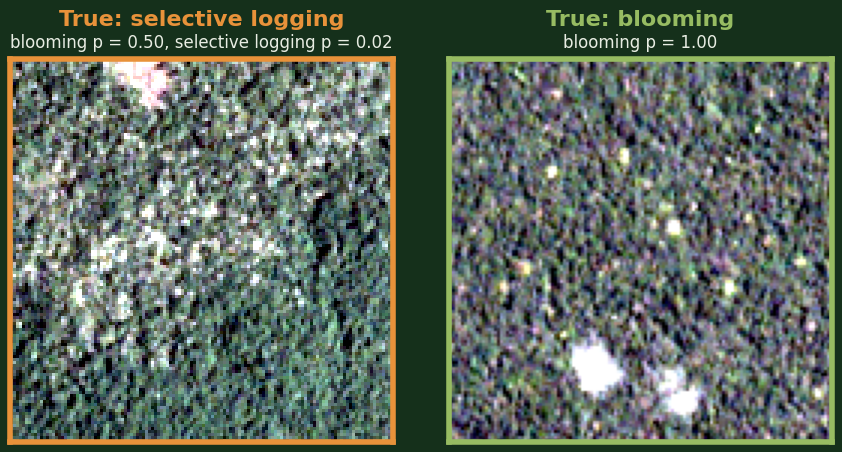

chips used (cache indices): (16369, 17773)
other logging candidates (cache indices), try them with PAIR = (index, blooming index): [36056, 36563, 13889, 16369]


,missed,blooming,cultivation,water,not_seen,habitation,agriculture,bare ground
selective_logging,50.0,36.0,28.0,28.0,8.0,NaN,NaN,NaN
slash_burn,60.0,NaN,NaN,22.0,28.0,23.0,22.0,NaN
artisinal_mine,8.0,NaN,NaN,NaN,0.0,50.0,50.0,62.0
conventional_mine,14.0,NaN,21.0,36.0,21.0,NaN,NaN,29.0


In [43]:

# ===== Cell B: a look-alike pair: a selective-logging chip the model called blooming, next to a real blooming chip
# Chips are picked from the seed-42 final run. To choose them yourself: PAIR = (logging chip index, blooming chip index)
PAIR = (16369, 17773)
A, B = "selective_logging", "blooming"
X128 = np.load(f"{CACHE}/X.npy", mmap_mode="r")             # the 128 px image cache (same folder as labels.json)

def natural_rgb(x, lo=2, hi=98, gamma=0.9):
    """(channels, H, W) chip -> (H, W, 3) image, each band stretched on its own (display only)."""
    img = np.transpose(np.asarray(x[:3], dtype=np.float32), (1, 2, 0))
    out = np.empty_like(img)
    for c in range(3):
        lo_, hi_ = np.percentile(img[..., c], [lo, hi])
        out[..., c] = np.clip((img[..., c] - lo_) / (hi_ - lo_ + 1e-6), 0, 1)
    return out ** gamma

r = RUN[FINAL]; ty, tp, tidx = r["ty"].astype(bool), r["tp"], r["tidx"]
pred = evaluate(FINAL)["pred"]["test"].astype(bool)
ja, jb, jc = labels.index(A), labels.index(B), labels.index("clear")
if PAIR is None:
    # logging chip: has selective logging, model missed it AND wrongly said blooming; most confident "blooming" first
    c1 = np.where(ty[:, ja] & ~pred[:, ja] & pred[:, jb] & ~ty[:, jb])[0]
    if not len(c1):                                          # fallback: missed logging chips, highest blooming probability
        c1 = np.where(ty[:, ja] & ~pred[:, ja] & ~ty[:, jb])[0]
        print("no logging chip was called blooming in seed 42; using the missed logging chip closest to it")
    c1 = c1[np.argsort(-tp[c1, jb])]
    # blooming chip: truly blooming (no logging), found by the model, clear weather; most confident first
    c2 = np.where(ty[:, jb] & pred[:, jb] & ~ty[:, ja] & ty[:, jc])[0]
    c2 = c2[np.argsort(-tp[c2, jb])]
    assert len(c1) and len(c2), "no suitable chips in the seed-42 run: set PAIR by hand"
    k1, k2 = c1[0], c2[0]
    PAIR = (int(tidx[k1]), int(tidx[k2]))
else:
    k1, k2 = [int(np.where(tidx == i)[0][0]) for i in PAIR]

fig, axes = plt.subplots(1, 2, figsize=(9, 5.1))
for ax, k, head, sub, col in [
        (axes[0], k1, "True: selective logging", f"blooming p = {tp[k1, jb]:.2f}, selective logging p = {tp[k1, ja]:.2f}", DECK["orange"]),
        (axes[1], k2, "True: blooming", f"blooming p = {tp[k2, jb]:.2f}", DECK["moss"])]:
    ax.imshow(natural_rgb(X128[int(tidx[k])])); ax.set_xticks([]); ax.set_yticks([])
    for sp in ax.spines.values(): sp.set_visible(True); sp.set_color(col); sp.set_linewidth(4)
    ax.set_title(head, fontsize=16, color=col, fontweight="bold", pad=24)
    ax.text(0.5, 1.02, sub, transform=ax.transAxes, ha="center", va="bottom", fontsize=12, color=DECK["text"])
fig.tight_layout(); fig.savefig(f"{OUT}/deck_lookalike.png"); plt.show()
print("chips used (cache indices):", PAIR)
if "c1" in globals():
    print("other logging candidates (cache indices), try them with PAIR = (index, blooming index):",
          [int(tidx[k]) for k in c1[1:6]])
display(pd.DataFrame(summary).T)
